# Final Dataset Full

In [11]:
# -*- coding: utf-8 -*-
"""
EDA_bahan_ppt.py - menyiapkan SEMUA bahan untuk PPT EDA, sesuai catatan dosen:

  1. contoh dataset udang          -> fig_contoh_*.png
  2. aplikasi EDA ada di mana      -> fig_posisi_eda_pipeline.png
  3. output setelah pakai EDA      -> manifest_dataset_setelah_EDA.csv + fig_funnel_output_eda.png
  4. EDA yang dilakukan apa        -> tabel "EDA yang dilakukan"
  5. temuan EDA di tesis           -> daftar temuan otomatis (berisi angka)
  6. jika kondisi X maka lakukan Y -> tabel keputusan "jika-maka" (dengan jumlah kasus nyata)
  7. pakai tools apa               -> tabel tools + versi
  8. distribusi gambar             -> fig_distribusi_*.png, fig_cakupan_label_heatmap.png, dst.

Masukan : CSV hasil program utama (eda_blur_per_citra.csv, eda_cakupan_label_per_kondisi.csv)
          + folder citra dan folder JSON (hanya untuk gambar contoh/overlay).
Keluaran: folder  <CSV_DIR>\\bahan_ppt  berisi PNG, CSV, dan bahan_ppt.md (ringkasan siap salin).
Tidak membaca ulang seluruh citra, jadi cepat.
"""
import glob
import json
import os
import platform
import re
import sys
import traceback

import cv2
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns
from matplotlib.patches import FancyBboxPatch

# =====================================================================
# KONFIGURASI
# =====================================================================
CSV_DIR = r"C:\Users\Lenovo\Documents\S2\Semester 1\Sains Data\output_eda"
IMG_DIR = r"C:\Users\Lenovo\Documents\S2\Program\Dataset\Raw_Dataset"
LBL_DIR = r"C:\Users\Lenovo\Documents\S2\Program\Dataset\Labeling\Json"
OUT = os.path.join(CSV_DIR, "bahan_ppt")
SEED = 42
BLUR_PCTL = 0.01          # ambang "kandidat severe blur" = persentil ke-1 per posisi lampu
EKSTREM_FRAC = 0.50       # box > 50% luas frame dianggap ekstrem (cek label)
RES_STANDAR = (1920, 1080)

os.makedirs(OUT, exist_ok=True)
rng = np.random.default_rng(SEED)
sns.set_theme(style="whitegrid")
pd.set_option("display.width", 250)
pd.set_option("display.max_columns", None)

# =====================================================================
# KONSTANTA & HELPER
# =====================================================================
KELAS = {"small": "Small (4-7 cm)", "medium": "Medium (8-10 cm)", "large": "Large (11-15 cm)"}
URUT = list(KELAS.values())
KEY_OF = {v: k for k, v in KELAS.items()}
SIZE_FOLDERS = {"Small_Shrimp": "small", "Medium_Shrimp": "medium", "Large_Shrimp": "large"}
WARNA_URUT = ["Abu", "Biru", "Hijau", "Hitam", "Krem", "Kuning", "Merah", "Putih"]
WARNA = {w.lower() for w in WARNA_URUT}
ALIAS = {"hljau": "hijau"}
PWM_OK = {50, 100, 150, 200, 255}
POSISI = {"a": "Atas", "b": "Bawah"}
POS_KEY = {"Atas": "a", "Bawah": "b"}
LAMPU_PWM = [f"{l}-{p}" for l in ("Atas", "Bawah") for p in (50, 100, 150, 200, 255)]
PAL = {"Atas": "#2b5c8f", "Bawah": "#36a970"}
JSON_PAT = re.compile(r"^(?:labels[_-])?(small|medium|large)[_-]([a-z]+)[_-]([ab])[_-](\d+)(?:[_-].*)?$", re.I)
FOLDER_OK = re.compile(r"^(?:[kKlL]_)?(Abu|Biru|Hijau|Hitam|Krem|Kuning|Merah|Putih)_[AB]_(50|100|150|200|255)$")


def parse_meta(name):
    tok = [ALIAS.get(t, t) for t in os.path.splitext(os.path.basename(name))[0].lower().split("_")]
    warna = next((t for t in tok if t in WARNA), None)
    posisi = next((t for t in tok if t in ("a", "b")), None)
    if posisi is None and tok and len(tok[0]) == 2 and tok[0][1] in "ab":
        posisi = tok[0][1]
    pwm = next((int(t) for t in tok if t.isdigit() and int(t) in PWM_OK), None)
    return warna, posisi, pwm


def meta_from_json_name(path):
    m = JSON_PAT.match(os.path.splitext(os.path.basename(path))[0])
    if not m:
        return None
    kelas, warna, posisi, pwm = m.groups()
    return kelas.lower(), ALIAS.get(warna.lower(), warna.lower()), posisi.lower(), int(pwm)


def simpan(nama):
    plt.tight_layout()
    plt.savefig(os.path.join(OUT, nama), dpi=200, bbox_inches="tight")
    plt.close("all")
    print("   gambar:", nama)


def simpan_csv(d, nama, index=True):
    d.to_csv(os.path.join(OUT, nama), index=index)
    print("   tabel :", nama)


def md_tabel(d, index=True, fmt="{:,.2f}"):
    d = d.reset_index() if index else d.copy()
    cols = list(d.columns)
    baris = ["| " + " | ".join(map(str, cols)) + " |", "|" + "---|" * len(cols)]
    for _, r in d.iterrows():
        sel = []
        for v in r:
            if isinstance(v, (int, np.integer)):
                sel.append(f"{v:,}")
            elif isinstance(v, (float, np.floating)):
                sel.append("" if np.isnan(v) else fmt.format(v))
            else:
                sel.append(str(v))
        baris.append("| " + " | ".join(sel) + " |")
    return "\n".join(baris)


def jalankan(nama, fn):
    print(f"\n>> {nama}")
    try:
        return fn()
    except Exception:
        print(f"[GAGAL] {nama} (bagian lain tetap dilanjutkan):")
        traceback.print_exc()
        return None


# =====================================================================
# MUAT DATA
# =====================================================================
df = pd.read_csv(os.path.join(CSV_DIR, "eda_blur_per_citra.csv"))
cov = pd.read_csv(os.path.join(CSV_DIR, "eda_cakupan_label_per_kondisi.csv"))
for d in (df, cov):
    d["warna_bg"] = d["warna_bg"].str.strip().str.capitalize()
    d["kond"] = d["posisi_lampu"] + "-" + d["pwm_cahaya"].astype(int).astype(str)

df["ada_label"] = df["box_area_px"] > 0
df["box_area_frac"] = np.where(df["ada_label"], df["box_area_px"] / (df["img_w"] * df["img_h"]), np.nan)
rasio = df["blur_score"] / df["blur_norm"].replace(0, np.nan)
df["brightness_est"] = np.sqrt((rasio - 1e-6).clip(lower=0))      # kecerahan rata-rata (0-255) hasil turunan blur_norm
df["frame_no"] = df["filename"].str.extract(r"_(\d+)\.[A-Za-z0-9]+$")[0].astype(float)
df["kelas_ord"] = df["ukuran_kelas"].map({k: i + 1 for i, k in enumerate(URUT)})
df["lampu_bawah"] = (df["posisi_lampu"] == "Bawah").astype(int)
lab = df[df["ada_label"]].copy()
KOND4 = ["ukuran_kelas", "warna_bg", "posisi_lampu", "pwm_cahaya"]

N_ALL = len(df)
print(f"Data dimuat: {N_ALL:,} citra, {int(df['ada_label'].sum()):,} berlabel, {len(cov)} kondisi.")
REPORT = {}      # bagian markdown per nomor catatan dosen


# =====================================================================
# 8. DISTRIBUSI GAMBAR
# =====================================================================
def sec_distribusi():
    ring = cov.groupby("ukuran_kelas").agg(n_kondisi=("kond", "size"), n_citra=("n_citra", "sum"),
                                           n_label=("n_label_cocok", "sum")).reindex(URUT)
    ring["cakupan_label_pct"] = 100 * ring["n_label"] / ring["n_citra"]
    ring["n_kondisi_berlabel"] = cov[cov["n_label_cocok"] > 0].groupby("ukuran_kelas").size().reindex(URUT).fillna(0).astype(int)
    simpan_csv(ring, "tabel_distribusi_per_kelas.csv")

    # (a) jumlah citra per kelas + per posisi lampu
    fig, ax = plt.subplots(1, 2, figsize=(11, 4))
    sns.barplot(x=ring.index, y=ring["n_citra"], hue=ring.index, order=URUT, palette="Set2", legend=False, ax=ax[0])
    for i, v in enumerate(ring["n_citra"]):
        ax[0].text(i, v, f"{int(v):,}", ha="center", va="bottom", fontsize=9)
    ax[0].set_title("Jumlah citra per kelas ukuran"); ax[0].set_xlabel(""); ax[0].set_ylabel("Jumlah citra")
    pv = cov.pivot_table(index="ukuran_kelas", columns="posisi_lampu", values="n_citra", aggfunc="sum").reindex(URUT)
    pv[["Atas", "Bawah"]].plot(kind="bar", stacked=True, color=[PAL["Atas"], PAL["Bawah"]], ax=ax[1], rot=0)
    ax[1].set_title("Per posisi lampu"); ax[1].set_xlabel(""); ax[1].set_ylabel("Jumlah citra"); ax[1].legend(title="Posisi lampu")
    simpan("fig_distribusi_jumlah_citra.png")

    # (b) heatmap jumlah citra per kondisi, tiap kelas
    for nama, kolom, fmt, cmap, kw, judul in [
        ("fig_distribusi_kondisi_heatmap.png", "n_citra", ".0f", "Blues", {}, "Jumlah citra"),
        ("fig_cakupan_label_heatmap.png", "cakupan_pct", ".0f", "RdYlGn", dict(vmin=0, vmax=100), "Cakupan label (%)"),
    ]:
        fig, axes = plt.subplots(1, 3, figsize=(18, 4.2), sharey=True)
        for ax, k in zip(axes, URUT):
            pt = (cov[cov["ukuran_kelas"] == k].pivot_table(index="warna_bg", columns="kond", values=kolom, aggfunc="mean")
                  .reindex(index=WARNA_URUT, columns=LAMPU_PWM))
            sns.heatmap(pt, annot=True, fmt=fmt, cmap=cmap, cbar=False, linewidths=.5, ax=ax, annot_kws={"size": 7}, **kw)
            ax.set_title(f"{k}", fontsize=10); ax.set_xlabel("Posisi lampu - PWM"); ax.set_ylabel("")
            ax.tick_params(axis="x", labelsize=7)
        fig.suptitle(f"{judul} per kondisi (warna alas x lampu-PWM)", fontweight="bold")
        simpan(nama)

    # (c) resolusi
    res = df.groupby(["ukuran_kelas", "img_w", "img_h"]).size().rename("n_citra").reset_index()
    res["resolusi"] = res["img_w"].astype(int).astype(str) + "x" + res["img_h"].astype(int).astype(str)
    simpan_csv(res, "tabel_resolusi.csv", index=False)
    pr = res.pivot_table(index="ukuran_kelas", columns="resolusi", values="n_citra", aggfunc="sum").reindex(URUT).fillna(0)
    pr.plot(kind="bar", stacked=True, figsize=(7, 4), rot=0, colormap="Set2")
    plt.title("Resolusi citra per kelas"); plt.xlabel(""); plt.ylabel("Jumlah citra")
    simpan("fig_distribusi_resolusi.png")

    REPORT[8] = (ring, res)


jalankan("8. distribusi gambar", sec_distribusi)


# =====================================================================
# 4/5. STATISTIK, KORELASI, UKURAN BOX
# =====================================================================
def deskriptif(d, kolom):
    g = d.groupby("ukuran_kelas")[kolom]
    t = g.agg(n="count", mean="mean", median="median", sd="std", min="min", max="max")
    t["q1"], t["q3"] = g.quantile(.25), g.quantile(.75)
    t["iqr"] = t["q3"] - t["q1"]
    t["skew"] = g.skew()
    return t.reindex(URUT)


def sec_statistik():
    # tabel deskriptif beberapa variabel
    bagian = []
    for kolom, nama in [("box_area_px", "Luas box (px2)"), ("box_area_frac", "Luas box / luas frame"),
                        ("blur_score", "Blur score (Var. Laplacian)"), ("brightness_est", "Kecerahan (turunan)")]:
        t = deskriptif(lab if kolom.startswith("box") else df, kolom)
        t.insert(0, "variabel", nama)
        bagian.append(t)
    desk = pd.concat(bagian)
    simpan_csv(desk, "tabel_deskriptif.csv")

    # IQR luas box per kelas
    q = lab.groupby("ukuran_kelas")["box_area_px"].quantile([.25, .75]).unstack()
    q.columns = ["q1", "q3"]
    q["iqr"] = q["q3"] - q["q1"]
    q["batas_bawah"], q["batas_atas"] = q["q1"] - 1.5 * q["iqr"], q["q3"] + 1.5 * q["iqr"]
    q = q.reindex(URUT)
    n_out = {}
    for k in URUT:
        s = lab.loc[lab["ukuran_kelas"] == k, "box_area_px"]
        n_out[k] = int(((s < q.loc[k, "batas_bawah"]) | (s > q.loc[k, "batas_atas"])).sum())
    q["n"] = lab.groupby("ukuran_kelas").size().reindex(URUT)
    q["n_outlier"] = pd.Series(n_out)
    q["outlier_pct"] = 100 * q["n_outlier"] / q["n"]
    simpan_csv(q, "tabel_iqr_outlier_luas_box.csv")
    df["flag_area_outlier"] = df["ada_label"] & ((df["box_area_px"] < df["ukuran_kelas"].map(q["batas_bawah"])) |
                                                 (df["box_area_px"] > df["ukuran_kelas"].map(q["batas_atas"])))
    lab["flag_area_outlier"] = df.loc[lab.index, "flag_area_outlier"]

    # sebaran outlier per kondisi
    ok = lab.groupby(KOND4)["flag_area_outlier"].agg(n_frame="size", n_outlier="sum").reset_index()
    ok = ok[ok["n_outlier"] > 0].sort_values("n_outlier", ascending=False)
    simpan_csv(ok, "tabel_outlier_per_kondisi.csv", index=False)

    # boxplot luas box per kelas
    fig, ax = plt.subplots(1, 2, figsize=(12, 4.5))
    sns.boxplot(data=lab, x="ukuran_kelas", y="box_area_px", order=URUT, hue="ukuran_kelas", hue_order=URUT,
                palette="Set2", legend=False, showmeans=True, fliersize=2, ax=ax[0])
    ax[0].set_title("Luas bounding box polygon (px2)"); ax[0].set_xlabel(""); ax[0].set_ylabel("px2")
    sns.boxplot(data=lab, x="ukuran_kelas", y="box_area_frac", order=URUT, hue="ukuran_kelas", hue_order=URUT,
                palette="Set2", legend=False, showmeans=True, fliersize=2, ax=ax[1])
    ax[1].set_title("Luas box relatif terhadap frame"); ax[1].set_xlabel(""); ax[1].set_ylabel("luas box / luas frame")
    simpan("fig_boxplot_luas_box.png")

    # luas box menurut posisi lampu (sensitivitas pengukuran terhadap kondisi akuisisi)
    plt.figure(figsize=(8, 4.5))
    sns.boxplot(data=lab, x="ukuran_kelas", y="box_area_frac", hue="posisi_lampu", order=URUT, hue_order=["Atas", "Bawah"],
                palette=PAL, showfliers=False)
    plt.title("Luas box relatif menurut posisi lampu"); plt.xlabel(""); plt.ylabel("luas box / luas frame")
    plt.legend(title="Posisi lampu")
    simpan("fig_luas_box_vs_lampu.png")

    # median luas relatif per kondisi (heatmap)
    fig, axes = plt.subplots(1, 3, figsize=(18, 4.2), sharey=True)
    for ax, k in zip(axes, URUT):
        pt = (lab[lab["ukuran_kelas"] == k].pivot_table(index="warna_bg", columns="kond", values="box_area_frac", aggfunc="median") * 100)
        pt = pt.reindex(index=WARNA_URUT, columns=LAMPU_PWM)
        sns.heatmap(pt, annot=True, fmt=".1f", cmap="YlGnBu", cbar=False, linewidths=.5, ax=ax, annot_kws={"size": 7})
        ax.set_title(k, fontsize=10); ax.set_xlabel("Posisi lampu - PWM"); ax.set_ylabel("")
        ax.tick_params(axis="x", labelsize=7)
    fig.suptitle("Median luas box (% luas frame) per kondisi", fontweight="bold")
    simpan("fig_luas_box_median_kondisi.png")

    # sensitivitas: rentang median antar kondisi (kondisi dengan >=30 frame)
    cm = lab.groupby(["ukuran_kelas", "warna_bg", "kond"])["box_area_frac"].agg(["median", "size"]).reset_index()
    cm = cm[cm["size"] >= 30]
    sens = cm.groupby("ukuran_kelas")["median"].agg(median_antar_kondisi="median", minimum="min", maksimum="max").reindex(URUT)
    sens["rentang_relatif_pct"] = 100 * (sens["maksimum"] - sens["minimum"]) / sens["median_antar_kondisi"]
    simpan_csv(sens, "tabel_sensitivitas_luas_box_antar_kondisi.csv")

    # blur: heatmap warna x kondisi
    fig, ax = plt.subplots(1, 2, figsize=(15, 4.2), sharey=True)
    p1 = df.pivot_table(index="warna_bg", columns="kond", values="blur_score", aggfunc="mean").reindex(index=WARNA_URUT, columns=LAMPU_PWM)
    sns.heatmap(p1, annot=True, fmt=".1f", cmap="YlGn", cbar=False, linewidths=.5, ax=ax[0], annot_kws={"size": 7})
    ax[0].set_title("Rata-rata blur score (mentah)"); ax[0].set_xlabel("Posisi lampu - PWM"); ax[0].set_ylabel("")
    p2 = df.pivot_table(index="warna_bg", columns="kond", values="blur_norm", aggfunc="median").reindex(index=WARNA_URUT, columns=LAMPU_PWM) * 1000
    sns.heatmap(p2, annot=True, fmt=".1f", cmap="YlGn", cbar=False, linewidths=.5, ax=ax[1], annot_kws={"size": 7})
    ax[1].set_title("Median blur_norm x 1000 (dinormalkan kecerahan)"); ax[1].set_xlabel("Posisi lampu - PWM"); ax[1].set_ylabel("")
    for a in ax:
        a.tick_params(axis="x", labelsize=7)
    simpan("fig_blur_heatmap_kondisi.png")

    # korelasi Spearman
    kol = ["pwm_cahaya", "lampu_bawah", "kelas_ord", "blur_score", "blur_norm", "brightness_est", "box_area_frac"]
    nama = {"pwm_cahaya": "PWM", "lampu_bawah": "Lampu bawah", "kelas_ord": "Kelas (1-3)", "blur_score": "Blur score",
            "blur_norm": "Blur norm", "brightness_est": "Kecerahan", "box_area_frac": "Luas box rel."}
    cor = df[kol].rename(columns=nama).corr(method="spearman")
    plt.figure(figsize=(7.5, 6))
    sns.heatmap(cor, annot=True, fmt=".2f", cmap="coolwarm", vmin=-1, vmax=1, linewidths=.5, cbar_kws={"label": "Spearman"})
    plt.title("Korelasi antar variabel")
    simpan("fig_korelasi_spearman.png")
    simpan_csv(cor, "tabel_korelasi_spearman.csv")

    REPORT[4] = (desk, q, ok, sens, cor)


jalankan("4/5. statistik, outlier, korelasi", sec_statistik)

# =====================================================================
# 3. OUTPUT SETELAH EDA: manifest + funnel
# =====================================================================
FUNNEL = {}


def sec_manifest():
    if "flag_area_outlier" not in df:
        df["flag_area_outlier"] = False
    ambang = df.groupby("posisi_lampu")["blur_score"].transform(lambda s: s.quantile(BLUR_PCTL))
    df["flag_blur_kandidat"] = df["blur_score"] < ambang
    df["flag_ekstrem"] = df["box_area_frac"] > EKSTREM_FRAC
    df["flag_resolusi"] = ~((df["img_w"] == RES_STANDAR[0]) & (df["img_h"] == RES_STANDAR[1]))
    bermasalah = df["flag_blur_kandidat"] | df["flag_area_outlier"] | df["flag_ekstrem"] | df["flag_resolusi"]
    df["status"] = np.where(~df["ada_label"], "perlu_label", np.where(bermasalah, "tinjau", "layak_training"))
    kol = KOND4 + ["filename", "img_w", "img_h", "ada_label", "blur_score", "blur_norm", "box_area_px", "box_area_frac",
                   "flag_blur_kandidat", "flag_area_outlier", "flag_ekstrem", "flag_resolusi", "status"]
    simpan_csv(df[kol], "manifest_dataset_setelah_EDA.csv", index=False)

    # funnel bertahap
    m1 = df["ada_label"]
    m2 = m1 & ~df["flag_blur_kandidat"]
    m3 = m2 & ~df["flag_area_outlier"] & ~df["flag_ekstrem"]
    m4 = m3 & ~df["flag_resolusi"]
    langkah = [("Citra terbaca", pd.Series(True, index=df.index)), ("Berlabel (JSON)", m1),
               ("Lolos kandidat blur", m2), ("Lolos outlier luas box", m3), ("Lolos resolusi standar = layak", m4)]
    tab = pd.DataFrame({n: m.groupby(df["ukuran_kelas"]).sum().reindex(URUT) for n, m in langkah}).astype(int)
    tab.loc["Semua kelas"] = tab.sum()
    simpan_csv(tab.T, "tabel_funnel_output_eda.csv")
    FUNNEL["tab"] = tab

    total = [int(m.sum()) for _, m in langkah]
    plt.figure(figsize=(9, 4))
    ax = sns.barplot(y=[n for n, _ in langkah], x=total, color="#0F766E")
    for i, v in enumerate(total):
        pct = f"  ({100 * v / total[0]:.1f}% dari semua citra)"
        ax.text(v, i, f" {v:,}{pct}", va="center", fontsize=9)
    ax.set_xlim(0, total[0] * 1.45)
    ax.set_title("Output EDA: dari seluruh citra menjadi data layak latih")
    ax.set_xlabel("Jumlah citra")
    simpan("fig_funnel_output_eda.png")

    st = df.groupby(["ukuran_kelas", "status"]).size().unstack(fill_value=0).reindex(URUT)
    simpan_csv(st, "tabel_status_per_kelas.csv")
    FUNNEL["status"] = st


jalankan("3. manifest dan funnel", sec_manifest)


# =====================================================================
# 1. CONTOH DATASET (overlay polygon)
# =====================================================================
def sec_contoh():
    if not (os.path.isdir(IMG_DIR) and os.path.isdir(LBL_DIR)):
        print("   IMG_DIR/LBL_DIR tidak ditemukan -> bagian contoh dilewati")
        return
    peta_json = {}
    for jf in glob.glob(os.path.join(LBL_DIR, "**", "*.json"), recursive=True):
        meta = meta_from_json_name(jf)
        if meta:
            peta_json.setdefault(meta, []).append(jf)
    peta_img = {}
    for fk, kk in SIZE_FOLDERS.items():
        kd = os.path.join(IMG_DIR, fk)
        if not os.path.isdir(kd):
            continue
        for sub in os.listdir(kd):
            sd = os.path.join(kd, sub)
            if os.path.isdir(sd):
                w, p, pw = parse_meta(sub)
                if None not in (w, p, pw):
                    peta_img[(kk, w, p, pw)] = sd
    cache_json, cache_list = {}, {}

    def muat(path):
        if path not in cache_json:
            with open(path, "r", encoding="utf-8") as f:
                cache_json[path] = json.load(f)
        return cache_json[path]

    def daftar(folder):
        if folder not in cache_list:
            cache_list[folder] = {f.lower(): f for f in os.listdir(folder) if f.lower().endswith((".jpg", ".png"))}
        return cache_list[folder]

    def ambil(key, nama=None, boleh_tanpa_label=True):
        """Kembalikan (gambar RGB 640 px, ada_polygon) atau None."""
        folder = peta_img.get(key)
        if folder is None:
            return None
        files = daftar(folder)
        poly = None
        pilihan = None
        for jf in peta_json.get(key, []):
            data = muat(jf)
            if nama is not None:
                kunci = next((k for k in data if k.lower() == nama.lower()), None)
                cand = [kunci] if kunci else []
            else:
                cand = sorted(k for k in data if k.lower() in files)
            if cand:
                pilihan = cand[int(rng.integers(len(cand)))]
                reg = data[pilihan]["regions"]
                reg = list(reg.values())[0] if isinstance(reg, dict) else reg[0]
                sa = reg["shape_attributes"]
                poly = list(zip(sa["all_points_x"], sa["all_points_y"]))
                break
        if pilihan is None:
            if nama is not None or not boleh_tanpa_label or not files:
                return None
            pilihan = sorted(files)[int(rng.integers(len(files)))]
        path = os.path.join(folder, files.get(pilihan.lower(), pilihan))
        img = cv2.imread(path)
        if img is None:
            return None
        h, w = img.shape[:2]
        s = 640 / w
        im = cv2.resize(img, (640, int(h * s)))
        if poly:
            pts = (np.array(poly, float) * s).astype(np.int32).reshape(-1, 1, 2)
            ov = im.copy()
            cv2.fillPoly(ov, [pts], (0, 255, 0))
            im = cv2.addWeighted(ov, 0.25, im, 0.75, 0)
            cv2.polylines(im, [pts], True, (0, 255, 0), 2)
            x, y, bw, bh = cv2.boundingRect(pts)
            cv2.rectangle(im, (x, y), (x + bw, y + bh), (255, 200, 0), 1)
        return cv2.cvtColor(im, cv2.COLOR_BGR2RGB), bool(poly)

    def key_dari(kelas_label, warna, lampu, pwm):
        return KEY_OF[kelas_label], warna.lower(), POS_KEY[lampu], int(pwm)

    def montase(tiles, baris, kolom, nama_file, judul):
        fig, axes = plt.subplots(baris, kolom, figsize=(kolom * 4.3, baris * 2.7), squeeze=False)
        for ax in axes.ravel():
            ax.axis("off")
        for ax, (img, jdl) in zip(axes.ravel(), tiles):
            if img is not None:
                ax.imshow(img)
            else:
                ax.text(0.5, 0.5, "tidak tersedia", ha="center", va="center", transform=ax.transAxes)
            ax.set_title(jdl, fontsize=8.5)
        fig.suptitle(judul, fontweight="bold")
        simpan(nama_file)

    def pilih_kondisi(kelas_label, warna, lampu, pwm):
        """Kondisi berlabel terdekat dengan permintaan."""
        c = cov[(cov["ukuran_kelas"] == kelas_label) & (cov["n_label_cocok"] > 0)]
        if c.empty:
            return None
        pers = c[(c["warna_bg"] == warna) & (c["posisi_lampu"] == lampu)]
        if not pers.empty:
            r = pers.iloc[(pers["pwm_cahaya"] - pwm).abs().argsort().iloc[0]]
        else:
            r = c.iloc[int(rng.integers(len(c)))]
        return r["warna_bg"], r["posisi_lampu"], int(r["pwm_cahaya"])

    # --- Gambar 1: contoh tiap kelas pada beberapa warna alas / lampu
    spek = [("Putih", "Bawah", 200), ("Krem", "Atas", 200), ("Biru", "Bawah", 200), ("Merah", "Atas", 200)]
    tiles = []
    for k in URUT:
        for w, l, p in spek:
            kond = pilih_kondisi(k, w, l, p)
            hasil = ambil(key_dari(k, *kond)) if kond else None
            tiles.append((hasil[0] if hasil else None, f"{k.split()[0]} | {kond[0]} | {kond[1]} | PWM {kond[2]}" if kond else k))
    montase(tiles, 3, 4, "fig_contoh_dataset_per_kelas.png",
            "Contoh dataset udang vaname: 3 kelas ukuran x variasi warna alas dan posisi lampu (hijau = polygon label)")

    # --- Gambar 2: variasi lampu dan PWM (satu kelas, satu warna)
    skor = (cov[cov["n_label_cocok"] > 0].groupby(["ukuran_kelas", "warna_bg"]).size().rename("n").reset_index())
    skor["pref"] = (skor["ukuran_kelas"] == URUT[1]).astype(int) * 2 + (skor["warna_bg"] == "Biru").astype(int)
    pil = skor.sort_values(["n", "pref"], ascending=False).iloc[0]
    kk, ww = pil["ukuran_kelas"], pil["warna_bg"]
    tiles = []
    for l in ("Atas", "Bawah"):
        for p in (50, 100, 150, 200, 255):
            hasil = ambil(key_dari(kk, ww, l, p))
            ket = "" if (hasil and hasil[1]) else " (tanpa label)"
            tiles.append((hasil[0] if hasil else None, f"{l} | PWM {p}{ket}"))
    montase(tiles, 2, 5, "fig_contoh_variasi_lampu_pwm.png", f"Variasi posisi lampu dan PWM - kelas {kk}, alas {ww}")

    # --- Gambar 3: kondisi tanpa label (Hitam, Hijau-Atas)
    tiles = []
    for filt, nama in [((cov["warna_bg"] == "Hitam"), "Hitam"), ((cov["warna_bg"] == "Hijau") & (cov["posisi_lampu"] == "Atas"), "Hijau-Atas")]:
        c = cov[filt & (cov["n_label_cocok"] == 0)]
        for k in URUT:
            ck = c[c["ukuran_kelas"] == k]
            if ck.empty:
                tiles.append((None, f"{nama} | {k.split()[0]}"))
                continue
            r = ck.iloc[int(rng.integers(len(ck)))]
            hasil = ambil(key_dari(k, r["warna_bg"], r["posisi_lampu"], r["pwm_cahaya"]))
            tiles.append((hasil[0] if hasil else None, f"{nama} | {k.split()[0]} | {r['posisi_lampu']} | PWM {int(r['pwm_cahaya'])} (belum berlabel)"))
    montase(tiles, 2, 3, "fig_contoh_kondisi_tanpa_label.png", "Contoh kondisi yang belum memiliki label")

    # --- Gambar 4: kasus ekstrem
    def baris_ekstrem(d, kolom, asc, n=3):
        return d.sort_values(kolom, ascending=asc).head(n)
    tiles = []
    for d, ket in [(baris_ekstrem(lab, "box_area_frac", False), "box terbesar"),
                   (baris_ekstrem(lab, "box_area_frac", True), "box terkecil"),
                   (baris_ekstrem(lab, "blur_score", True), "blur terendah")]:
        for _, r in d.iterrows():
            hasil = ambil(key_dari(r["ukuran_kelas"], r["warna_bg"], r["posisi_lampu"], r["pwm_cahaya"]), nama=r["filename"])
            tiles.append((hasil[0] if hasil else None,
                          f"{ket}: {r['ukuran_kelas'].split()[0]} {r['warna_bg']} {r['posisi_lampu']} PWM{int(r['pwm_cahaya'])} | box {100 * r['box_area_frac']:.1f}% frame | blur {r['blur_score']:.1f}"))
    montase(tiles, 3, 3, "fig_contoh_kasus_ekstrem.png", "Kasus ekstrem yang diverifikasi visual (kandidat salah label / citra buruk)")


jalankan("1. contoh dataset (overlay)", sec_contoh)


# =====================================================================
# 2. POSISI EDA DALAM PIPELINE
# =====================================================================
def sec_pipeline():
    fig, ax = plt.subplots(figsize=(15, 5))
    ax.set_xlim(0, 15); ax.set_ylim(0, 5); ax.axis("off")
    tahap = ["Akuisisi data\n(rig akuarium: kamera,\nlampu PWM, sensor)", "Pelabelan\n(polygon udang,\nformat VIA JSON)", "EDA\n(audit & analisis data)",
             "Preprocessing\n(filter blur,\nnormalisasi, resize)", "Split data\n(per rekaman/kondisi)", "YOLOv9-Seg\n(segmentasi udang)",
             "Kalibrasi px->cm\n=> panjang (cm)"]
    x0, lebar, jarak = 0.2, 1.85, 0.30
    for i, t in enumerate(tahap):
        x = x0 + i * (lebar + jarak)
        eda = (i == 2)
        ax.add_patch(FancyBboxPatch((x, 3.0), lebar, 1.4, boxstyle="round,pad=0.05", fc="#0F766E" if eda else "#E5E7EB",
                                    ec="#0F766E" if eda else "#9CA3AF", lw=2))
        ax.text(x + lebar / 2, 3.7, t, ha="center", va="center", fontsize=8.5, color="white" if eda else "#1F2933",
                fontweight="bold" if eda else "normal")
        if i < len(tahap) - 1:
            ax.annotate("", xy=(x + lebar + jarak - 0.03, 3.7), xytext=(x + lebar + 0.03, 3.7), arrowprops=dict(arrowstyle="->", color="#6B7280"))
    xe = x0 + 2 * (lebar + jarak) + lebar / 2
    keluaran = [("Daftar eksklusi / tinjau\n(manifest status data)", 3), ("Ambang blur & aturan outlier", 3),
                ("Rencana split\nanti-kebocoran", 4), ("Konfigurasi akuisisi acuan\n(lampu, PWM, alas)", 0)]
    ax.text(xe, 2.35, "Keluaran EDA yang dipakai tahap berikutnya", ha="center", fontsize=9.5, fontweight="bold", color="#0F766E")
    for j, (teks, target) in enumerate(keluaran):
        xt = 0.9 + j * 3.4
        ax.add_patch(FancyBboxPatch((xt, 0.35), 3.0, 1.2, boxstyle="round,pad=0.05", fc="#F0FDFA", ec="#0F766E"))
        ax.text(xt + 1.5, 0.95, teks, ha="center", va="center", fontsize=8.5)
        ax.annotate("", xy=(xt + 1.5, 1.6), xytext=(xe, 2.7), arrowprops=dict(arrowstyle="-", color="#0F766E", lw=1))
    ax.set_title("Posisi EDA dalam alur penelitian (data baseline 0,5 NTU)", fontweight="bold")
    simpan("fig_posisi_eda_pipeline.png")


jalankan("2. posisi EDA di pipeline", sec_pipeline)


# =====================================================================
# 6/7/4. TABEL: JIKA-MAKA, TOOLS, EDA YANG DILAKUKAN + TEMUAN
# =====================================================================
def versi(m):
    try:
        return __import__(m).__version__
    except Exception:
        return "-"


def sec_tabel_teks():
    # --- hitungan untuk aturan jika-maka
    n_tanpa_label = int((~df["ada_label"]).sum())
    kond_tanpa_json = cov[cov["n_label_cocok"] == 0]
    n_kond_tanpa = len(kond_tanpa_json)
    n_blur = int((df["ada_label"] & df["flag_blur_kandidat"]).sum()) if "flag_blur_kandidat" in df else 0
    n_outl = int(df["flag_area_outlier"].sum()) if "flag_area_outlier" in df else 0
    n_ekst = int(df["flag_ekstrem"].sum()) if "flag_ekstrem" in df else 0
    n_res = int((df["flag_resolusi"]).sum()) if "flag_resolusi" in df else 0
    n_folder_besar = int((cov["n_citra"] > 1000).sum())
    n_label_tak_cocok = int((cov["n_label_json"] - cov["n_label_cocok"]).clip(lower=0).sum())
    n_unreadable = int(max(cov["n_citra"].sum() - N_ALL, 0))
    d = df.dropna(subset=["frame_no"]).sort_values(KOND4 + ["frame_no"])
    gap = d.groupby(KOND4)["frame_no"].diff().dropna()
    share1 = float((gap == 1).mean()) if len(gap) else float("nan")
    nama_aneh = []
    if os.path.isdir(IMG_DIR):
        for fk in SIZE_FOLDERS:
            kd = os.path.join(IMG_DIR, fk)
            if os.path.isdir(kd):
                nama_aneh += [f"{fk}/{s}" for s in os.listdir(kd) if os.path.isdir(os.path.join(kd, s)) and not FOLDER_OK.match(s)]
    titik = None
    p = os.path.join(CSV_DIR, "eda_luas_polygon_per_frame.csv")
    if os.path.exists(p):
        titik = pd.read_csv(p, usecols=["ukuran_kelas", "n_titik"]).groupby("ukuran_kelas")["n_titik"].median().reindex(URUT)

    aturan = pd.DataFrame([
        ("Frame tidak punya label", n_tanpa_label, "Jangan dipakai untuk training segmentasi; prioritaskan pelabelan kondisi yang kosong"),
        ("Kondisi (warna x lampu x PWM) tanpa file JSON", n_kond_tanpa, "Tandai sebagai belum siap; lengkapi label atau keluarkan dari eksperimen sementara"),
        ("Blur score di bawah persentil ke-1 (per posisi lampu), berlabel", n_blur, "Periksa visual: buang bila benar-benar buram; pertahankan jika hanya noise ringan (uji robustness)"),
        ("Luas box di luar batas IQR per kelas", n_outl, "Periksa overlay: koreksi bila salah label; pertahankan bila variasi pose/jarak valid"),
        (f"Luas box > {int(EKSTREM_FRAC * 100)}% luas frame", n_ekst, "Anggap kandidat salah label; verifikasi sebelum training"),
        (f"Resolusi bukan {RES_STANDAR[0]}x{RES_STANDAR[1]}", n_res, "Resize ke resolusi standar (atau pisahkan) agar skala piksel seragam"),
        ("Folder kondisi berisi > 1000 citra", n_folder_besar, "Cek rekaman ganda/duplikat sebelum dihitung sebagai data independen"),
        ("Label JSON tanpa citra pasangan", n_label_tak_cocok, "Cek penamaan citra atau citra yang terhapus; sinkronkan"),
        ("Citra tidak terbaca (file ada, gagal dibuka)", n_unreadable, "Buang / unduh ulang"),
        ("Nama folder tidak baku (typo/huruf)", len(nama_aneh), "Seragamkan nama folder: " + (", ".join(nama_aneh[:6]) if nama_aneh else "-")),
        ("Frame berurutan (selisih nomor frame = 1)", f"{100 * share1:.1f}% pasangan" if share1 == share1 else "-",
         "Split per rekaman/kondisi, bukan per frame acak (hindari kebocoran)"),
    ], columns=["Jika kondisi", "Jumlah kasus", "Maka tindakan"])
    simpan_csv(aturan, "tabel_jika_maka.csv", index=False)

    versi_py = platform.python_version()
    tools = pd.DataFrame([
        ("Python", versi_py, "Bahasa pemrograman seluruh pipeline EDA"),
        ("OpenCV (cv2)", versi("cv2"), "Membaca citra, Variance of Laplacian (blur), menggambar overlay polygon"),
        ("NumPy", versi("numpy"), "Perhitungan luas bounding box polygon, kuartil"),
        ("pandas", versi("pandas"), "Agregasi per kelas/warna/lampu/PWM, tabel IQR, manifest"),
        ("Matplotlib", versi("matplotlib"), "Grafik dan montase gambar contoh"),
        ("Seaborn", versi("seaborn"), "Boxplot, barplot, heatmap, korelasi"),
        ("Format label", "VIA JSON (polygon) & YOLO-seg .txt", "Label polygon udang; JSON dibaca langsung untuk luas box"),
        ("ESP32", "-", "Kontrol PWM lampu dan sensor kekeruhan pada rig akuarium"),
    ], columns=["Tool", "Versi", "Peran dalam EDA"])
    simpan_csv(tools, "tabel_tools.csv", index=False)

    eda = pd.DataFrame([
        ("Audit integritas data", "Hitung file terbaca, kondisi lengkap, label-citra cocok, nama baku, resolusi", "Python + pandas + OpenCV", "tabel_jika_maka.csv, tabel_resolusi.csv"),
        ("Distribusi citra", "Jumlah citra per kelas dan kondisi (warna x lampu x PWM)", "pandas + Seaborn", "fig_distribusi_*.png"),
        ("Cakupan label", "Frame berlabel / seluruh citra per kondisi", "pandas + Seaborn", "fig_cakupan_label_heatmap.png"),
        ("Statistik deskriptif", "Mean, median, SD, kuartil, skewness per kelas", "pandas", "tabel_deskriptif.csv"),
        ("Ukuran objek (luas box polygon)", "Bounding box polygon dari JSON, absolut dan relatif terhadap frame", "NumPy + pandas", "fig_boxplot_luas_box.png"),
        ("Deteksi outlier", "IQR (Q1-1,5 IQR, Q3+1,5 IQR) per kelas", "pandas", "tabel_iqr_outlier_luas_box.csv"),
        ("Kualitas citra", "Variance of Laplacian (mentah dan dinormalkan kecerahan)", "OpenCV", "fig_blur_heatmap_kondisi.png"),
        ("Hubungan antar variabel", "Korelasi Spearman (PWM, lampu, kelas, blur, kecerahan, luas box)", "pandas + Seaborn", "fig_korelasi_spearman.png"),
        ("Inspeksi visual", "Overlay polygon pada contoh acak dan kasus ekstrem", "OpenCV + Matplotlib", "fig_contoh_*.png"),
        ("Pemeriksaan risiko kebocoran", "Selisih nomor frame berurutan dalam satu kondisi", "pandas", "tabel_jika_maka.csv"),
    ], columns=["EDA yang dilakukan", "Metode", "Tools", "Keluaran"])
    simpan_csv(eda, "tabel_eda_yang_dilakukan.csv", index=False)
    REPORT[67] = (aturan, tools, eda, titik, share1, nama_aneh)


jalankan("6/7/4. tabel jika-maka, tools, EDA yang dilakukan", sec_tabel_teks)


# =====================================================================
# 5. TEMUAN OTOMATIS + bahan_ppt.md
# =====================================================================
def sec_temuan_dan_md():
    T = []
    ring, res = REPORT.get(8, (None, None))
    if ring is not None:
        tot, lab_tot = int(ring["n_citra"].sum()), int(ring["n_label"].sum())
        T.append(f"Dataset baseline 0,5 NTU berisi {tot:,} citra pada {len(cov)} kondisi; "
                 f"Small {int(ring.loc[URUT[0], 'n_citra']):,}, Medium {int(ring.loc[URUT[1], 'n_citra']):,}, Large {int(ring.loc[URUT[2], 'n_citra']):,} (kelas tidak seimbang).")
        T.append(f"Label JSON terbaca untuk {lab_tot:,} frame ({100 * lab_tot / tot:.1f}%); cakupan per kelas: "
                 + ", ".join(f"{k.split()[0]} {ring.loc[k, 'cakupan_label_pct']:.1f}%" for k in URUT)
                 + f". {int((cov['n_label_cocok'] == 0).sum())} kondisi belum berlabel.")
    if lab is not None and len(lab):
        q = lab.groupby("ukuran_kelas")["box_area_px"].quantile([.25, .5, .75]).unstack()
        sep = all(q.loc[URUT[i], 0.75] < q.loc[URUT[i + 1], 0.25] for i in range(2))
        T.append("Median luas box polygon: " + "; ".join(f"{k.split()[0]} {q.loc[k, 0.5]:,.0f} px2" for k in URUT)
                 + (". Kotak Q1-Q3 antar kelas tidak tumpang tindih." if sep else ". Kotak Q1-Q3 antar kelas tumpang tindih sebagian."))
        mf = lab.groupby("ukuran_kelas")["box_area_frac"].median().reindex(URUT) * 100
        T.append("Dalam persen luas frame, median box: " + "; ".join(f"{k.split()[0]} {mf[k]:.1f}%" for k in URUT) + ".")
    ba = df.groupby("posisi_lampu")[["blur_score"]].mean()["blur_score"]
    bn = df.groupby("posisi_lampu")["blur_norm"].median()
    if {"Atas", "Bawah"} <= set(ba.index):
        T.append(f"Skor Laplacian mentah lampu Bawah {ba['Bawah']:.2f} vs Atas {ba['Atas']:.2f} ({ba['Bawah'] / ba['Atas']:.1f} kali); "
                 f"setelah dinormalkan kecerahan (median) rasio menjadi {bn['Bawah'] / bn['Atas']:.2f} kali.")
    bw = df[df["posisi_lampu"] == "Bawah"].groupby("warna_bg")["blur_score"].mean().sort_values(ascending=False)
    if len(bw):
        T.append(f"Pada lampu Bawah, alas dengan skor tertinggi: {bw.index[0]} ({bw.iloc[0]:.1f}); terendah: {bw.index[-1]} ({bw.iloc[-1]:.1f}).")
    for lampu in ("Atas", "Bawah"):
        s = df[df["posisi_lampu"] == lampu]
        T.append(f"Korelasi Spearman PWM dengan blur_score (lampu {lampu}) = {s['pwm_cahaya'].corr(s['blur_score'], method='spearman'):.2f}; "
                 f"dengan blur_norm = {s['pwm_cahaya'].corr(s['blur_norm'], method='spearman'):.2f}.")
    if "flag_area_outlier" in df:
        n_o = int(df["flag_area_outlier"].sum())
        T.append(f"Outlier IQR luas box: {n_o:,} frame ({100 * n_o / max(len(lab), 1):.2f}% dari berlabel)"
                 + ("; sebarannya per kondisi ada di tabel_outlier_per_kondisi.csv." if n_o else "."))
    if 67 in REPORT:
        _, _, _, titik, share1, aneh = REPORT[67]
        if share1 == share1:
            T.append(f"{100 * share1:.1f}% pasangan citra bersebelahan dalam satu kondisi memiliki nomor frame berurutan -> risiko kebocoran bila split acak per frame.")
        if titik is not None:
            T.append("Median jumlah titik polygon per kelas: " + ", ".join(f"{k.split()[0]} {titik[k]:.0f}" for k in URUT) + " (kehalusan label berbeda antar kelas).")
    if FUNNEL.get("tab") is not None:
        t = FUNNEL["tab"].loc["Semua kelas"]
        T.append(f"Setelah aturan EDA: {int(t.iloc[-1]):,} citra layak latih dari {int(t.iloc[0]):,} citra ({100 * t.iloc[-1] / t.iloc[0]:.1f}%).")
    if "flag_resolusi" in df:
        nr = int(df["flag_resolusi"].sum())
        T.append(f"Resolusi: {nr:,} citra ({100 * nr / N_ALL:.1f}%) bukan {RES_STANDAR[0]}x{RES_STANDAR[1]}." if nr else f"Seluruh citra berresolusi {RES_STANDAR[0]}x{RES_STANDAR[1]}.")

    md = ["# Bahan PPT EDA (otomatis)", "", "Semua angka dihitung dari CSV hasil run. Gambar dan tabel berada di folder yang sama.", ""]
    md += ["## 1. Contoh dataset udang", "", "- fig_contoh_dataset_per_kelas.png (3 kelas x variasi warna alas dan lampu)",
           "- fig_contoh_variasi_lampu_pwm.png (efek posisi lampu dan PWM)", "- fig_contoh_kondisi_tanpa_label.png (Hitam, Hijau-Atas)",
           "- fig_contoh_kasus_ekstrem.png (box terbesar/terkecil, blur terendah)", ""]
    md += ["## 2. Aplikasi EDA di mana", "", "- fig_posisi_eda_pipeline.png: EDA berada setelah akuisisi dan pelabelan, sebelum preprocessing, split, dan training.",
           "- Keluaran EDA: daftar eksklusi/tinjau, ambang blur dan aturan outlier, rencana split, konfigurasi akuisisi acuan.", ""]
    md += ["## 3. Output setelah EDA", "", "- manifest_dataset_setelah_EDA.csv (status per citra: layak_training / tinjau / perlu_label)",
           "- fig_funnel_output_eda.png", ""]
    if FUNNEL.get("tab") is not None:
        md += [md_tabel(FUNNEL["tab"].T.rename_axis("Tahap")), ""]
        md += ["Status per kelas:", "", md_tabel(FUNNEL["status"]), ""]
    if 67 in REPORT:
        aturan, tools, eda, _, _, _ = REPORT[67]
        md += ["## 4. EDA yang dilakukan", "", md_tabel(eda, index=False), ""]
    md += ["## 5. Temuan EDA", ""] + [f"{i}. {t}" for i, t in enumerate(T, 1)] + [""]
    if 67 in REPORT:
        md += ["## 6. Jika kondisi ini, maka dilakukan apa", "", md_tabel(aturan, index=False), ""]
        md += ["## 7. Tools", "", md_tabel(tools, index=False), ""]
    md += ["## 8. Distribusi gambar", "", "- fig_distribusi_jumlah_citra.png, fig_distribusi_kondisi_heatmap.png, fig_cakupan_label_heatmap.png, fig_distribusi_resolusi.png", ""]
    if ring is not None:
        md += [md_tabel(ring), ""]
    md += ["## Tambahan: statistik, outlier, korelasi", "", "- fig_boxplot_luas_box.png, fig_luas_box_vs_lampu.png, fig_luas_box_median_kondisi.png, fig_blur_heatmap_kondisi.png, fig_korelasi_spearman.png", ""]
    if 4 in REPORT:
        desk, q, ok, sens, cor = REPORT[4]
        md += ["IQR luas box per kelas:", "", md_tabel(q), "",
               "Sensitivitas luas box relatif antar kondisi (kondisi >= 30 frame):", "", md_tabel(sens), ""]
    with open(os.path.join(OUT, "bahan_ppt.md"), "w", encoding="utf-8") as f:
        f.write("\n".join(md))
    print("\n   ringkasan: bahan_ppt.md")
    print("\nTEMUAN OTOMATIS:")
    for i, t in enumerate(T, 1):
        print(f" {i}. {t}")


jalankan("5. temuan + bahan_ppt.md", sec_temuan_dan_md)
print("\nSelesai. Semua keluaran ada di:", OUT)

Data dimuat: 187,100 citra, 117,613 berlabel, 240 kondisi.

>> 8. distribusi gambar
   tabel : tabel_distribusi_per_kelas.csv
   gambar: fig_distribusi_jumlah_citra.png
   gambar: fig_distribusi_kondisi_heatmap.png
   gambar: fig_cakupan_label_heatmap.png
   tabel : tabel_resolusi.csv
   gambar: fig_distribusi_resolusi.png

>> 4/5. statistik, outlier, korelasi
   tabel : tabel_deskriptif.csv
   tabel : tabel_iqr_outlier_luas_box.csv
   tabel : tabel_outlier_per_kondisi.csv
   gambar: fig_boxplot_luas_box.png
   gambar: fig_luas_box_vs_lampu.png
   gambar: fig_luas_box_median_kondisi.png
   tabel : tabel_sensitivitas_luas_box_antar_kondisi.csv
   gambar: fig_blur_heatmap_kondisi.png
   gambar: fig_korelasi_spearman.png
   tabel : tabel_korelasi_spearman.csv

>> 3. manifest dan funnel
   tabel : manifest_dataset_setelah_EDA.csv
   tabel : tabel_funnel_output_eda.csv
   gambar: fig_funnel_output_eda.png
   tabel : tabel_status_per_kelas.csv

>> 1. contoh dataset (overlay)
   gambar: fig_c

# Dataset Full

[1/4] Membaca label JSON dari: C:\Users\Lenovo\Documents\S2\Program\Dataset\Labeling\Json
Entri label terbaca: 117729 dari 190 file JSON

[2/4] Memindai citra dari: C:\Users\Lenovo\Documents\S2\Program\Dataset\Raw_Dataset
  Small (4-7 cm)    K_Abu_A_100      citra=  350 diproses= 350 label=  187 cocok=  187
  Small (4-7 cm)    K_Abu_A_150      citra= 1000 diproses=1000 label=    0 cocok=    0
  Small (4-7 cm)    K_Abu_A_200      citra=  345 diproses= 345 label=  150 cocok=  150
  Small (4-7 cm)    K_Abu_A_255      citra=  400 diproses= 400 label=  334 cocok=  334
  Small (4-7 cm)    K_Abu_A_50       citra=  179 diproses= 179 label=   12 cocok=   12
  Small (4-7 cm)    K_Abu_B_100      citra=  411 diproses= 411 label=  368 cocok=  368
  Small (4-7 cm)    K_Abu_B_150      citra=  437 diproses= 437 label=  423 cocok=  423
  Small (4-7 cm)    K_Abu_B_200      citra=  471 diproses= 471 label=  449 cocok=  449
  Small (4-7 cm)    K_Abu_B_255      citra=  673 diproses= 673 label=  488 cocok= 

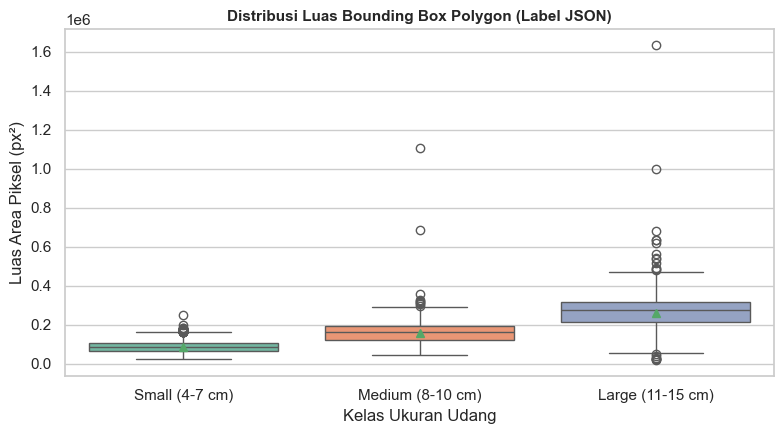

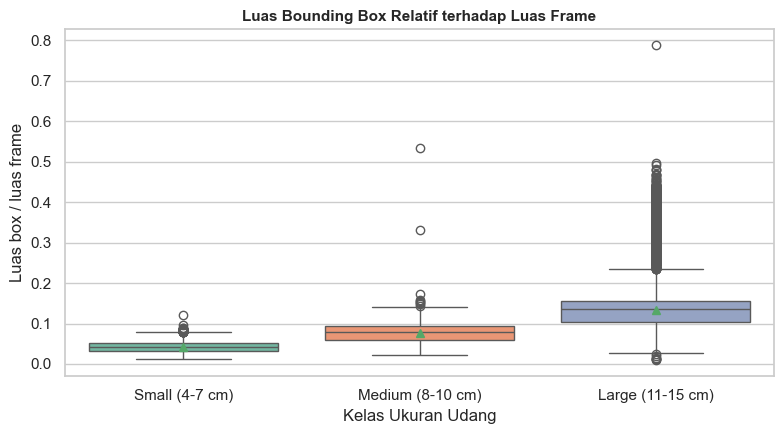

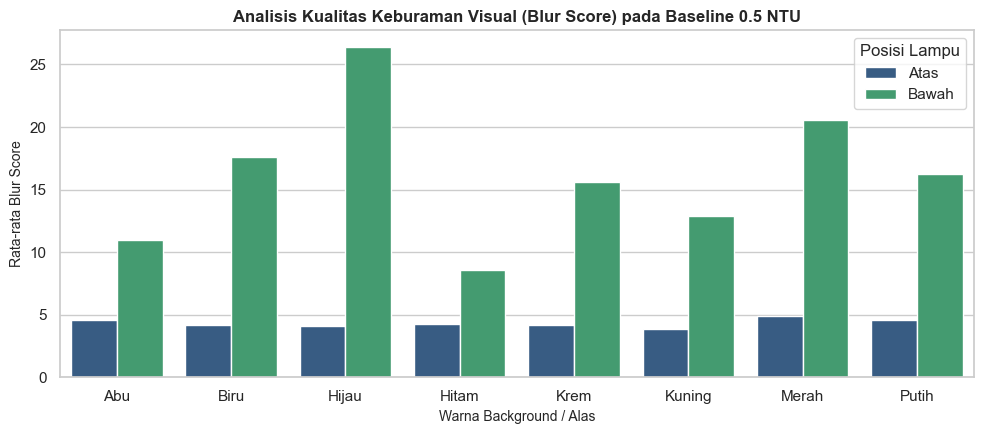

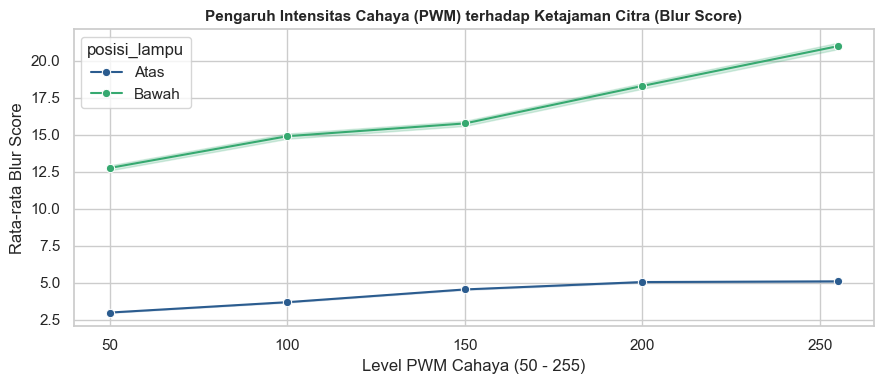

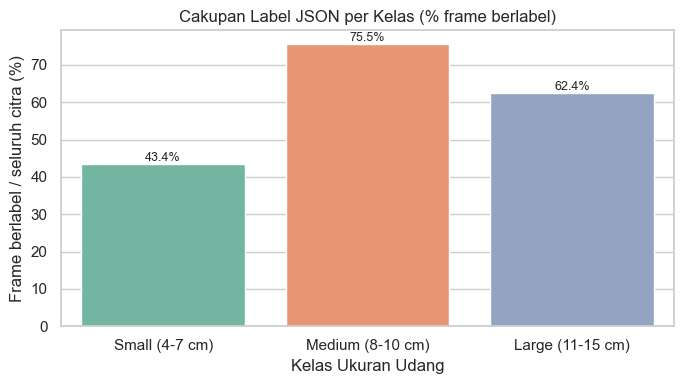

Selesai. Grafik dan tabel tersimpan di: C:\Users\Lenovo\Documents\S2\Semester 1\Sains Data\output_eda


In [ ]:
import glob
import itertools
import json
import os
import random
import re

import cv2
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns

# =====================================================================
# KONFIGURASI
# =====================================================================
IMG_DIR = r"C:\Users\Lenovo\Documents\S2\Program\Dataset\Raw_Dataset"
LBL_DIR = r"C:\Users\Lenovo\Documents\S2\Program\Dataset\Labeling\Json"   
OUT_DIR = r"C:\Users\Lenovo\Documents\S2\Semester 1\Sains Data\output_eda"  # folder output grafik & CSV

SAMPLE_PER_FOLDER = None   # citra acak per folder kondisi untuk blur; None = semua citra (lambat)
SEED = 42
REUSE_CSV = False         # True = lewati pembacaan citra jika CSV hasil sebelumnya sudah ada
SAVE_FIG = True           # simpan grafik sebagai PNG di OUT_DIR

os.makedirs(OUT_DIR, exist_ok=True)
pd.set_option("display.max_rows", None)
pd.set_option("display.max_columns", None)
pd.set_option("display.width", 250)
pd.set_option("display.float_format", lambda v: f"{v:,.2f}")

# =====================================================================
# KONSTANTA & HELPER
# =====================================================================
KELAS = {"small": "Small (4-7 cm)", "medium": "Medium (8-10 cm)", "large": "Large (11-15 cm)"}
SIZE_FOLDERS = {"Small_Shrimp": "small", "Medium_Shrimp": "medium", "Large_Shrimp": "large"}
WARNA = {"abu", "biru", "hijau", "hitam", "krem", "kuning", "merah", "putih"}
ALIAS = {"hljau": "hijau"}                      # koreksi typo yang pernah ditemukan
PWM_OK = {50, 100, 150, 200, 255}
POSISI = {"a": "Atas", "b": "Bawah"}
KOND = ["ukuran_kelas", "warna_bg", "posisi_lampu", "pwm_cahaya"]

# large_Biru_B_50.json, labels_large-abu-a-100_2025-...json, dst. (huruf besar/kecil bebas)
JSON_PAT = re.compile(
    r"^(?:labels[_-])?(small|medium|large)[_-]([a-z]+)[_-]([ab])[_-](\d+)(?:[_-].*)?$", re.I
)


def parse_meta(name):
    """Metadata dari nama folder/citra: (warna, posisi, pwm) huruf kecil; None jika tak terbaca."""
    tok = [ALIAS.get(t, t) for t in os.path.splitext(os.path.basename(name))[0].lower().split("_")]
    warna = next((t for t in tok if t in WARNA), None)
    posisi = next((t for t in tok if t in ("a", "b")), None)
    if posisi is None and tok and len(tok[0]) == 2 and tok[0][1] in "ab":   # mis. SB_ / SA_
        posisi = tok[0][1]
    pwm = next((int(t) for t in tok if t.isdigit() and int(t) in PWM_OK), None)
    return warna, posisi, pwm


def meta_from_json_name(path):
    """Metadata dari nama file JSON: (kelas_key, warna, posisi, pwm) atau None."""
    m = JSON_PAT.match(os.path.splitext(os.path.basename(path))[0])
    if not m:
        return None
    kelas, warna, posisi, pwm = m.groups()
    warna = ALIAS.get(warna.lower(), warna.lower())
    return kelas.lower(), warna, posisi.lower(), int(pwm)


def kelas_from_label(text):
    text = str(text).lower()
    return next((k for k in KELAS if k in text), None)


def poly_bbox(sa):
    x = np.asarray(sa["all_points_x"], float)
    y = np.asarray(sa["all_points_y"], float)
    return (x.max() - x.min()) * (y.max() - y.min()), x.max(), y.max(), len(x)


def tampil(nama_file):
    plt.tight_layout()
    if SAVE_FIG:
        plt.savefig(os.path.join(OUT_DIR, nama_file), dpi=200, bbox_inches="tight")
    plt.show()


# =====================================================================
# [1/4] BACA LABEL JSON
# =====================================================================
def load_labels():
    index, rows, bad, mismatch, dup = {}, [], [], [], 0
    files = sorted(glob.glob(os.path.join(LBL_DIR, "**", "*.json"), recursive=True))
    for jf in files:
        jname = os.path.basename(jf)
        try:
            with open(jf, "r", encoding="utf-8") as f:
                data = json.load(f)
        except Exception as e:
            bad.append((jname, f"gagal dibaca: {e}"))
            continue
        if not isinstance(data, dict):
            bad.append((jname, "bukan format VIA (dict nama_citra -> regions)"))
            continue
        meta = meta_from_json_name(jf)
        if meta is None:
            bad.append((jname, "nama file tidak sesuai pola -> metadata dibaca dari isi JSON"))

        for key_name, item in data.items():
            if not isinstance(item, dict) or "regions" not in item:
                continue
            fname = item.get("filename") or key_name
            regs = item["regions"]
            regs = list(regs.values()) if isinstance(regs, dict) else list(regs)

            area, n_reg, n_pts, xm, ym, kelas_isi = 0.0, 0, 0, 0.0, 0.0, None
            for r in regs:
                sa = r.get("shape_attributes", {})
                if "all_points_x" not in sa or len(sa["all_points_x"]) == 0:
                    continue
                a, x_max, y_max, npt = poly_bbox(sa)
                area += a
                n_reg += 1
                n_pts, xm, ym = max(n_pts, npt), max(xm, x_max), max(ym, y_max)
                kelas_isi = kelas_isi or kelas_from_label(r.get("region_attributes", {}).get("label", ""))
            if n_reg == 0:
                continue

            if meta:
                kk, wk, pk, pw = meta
                if kelas_isi and kelas_isi != kk:
                    mismatch.append((jname, fname, kk, kelas_isi))
            else:
                wk, pk, pw = parse_meta(fname)
                kk = kelas_isi
                if None in (kk, wk, pk, pw):
                    bad.append((jname, f"metadata tidak terbaca untuk entri: {fname}"))
                    continue

            d = index.setdefault((kk, wk, pk, pw), {})
            low = fname.lower()
            if low in d:
                dup += 1
            d[low] = (area, n_reg)
            rows.append(dict(
                sumber_json=jname, filename=fname, ukuran_kelas=KELAS[kk], warna_bg=wk.capitalize(),
                posisi_lampu=POSISI[pk], pwm_cahaya=pw, n_titik=n_pts,
                box_area_px=area, x_max=xm, y_max=ym,
            ))
    return index, pd.DataFrame(rows), bad, mismatch, dup


print("=" * 70)
print("[1/4] Membaca label JSON dari:", LBL_DIR)
print("=" * 70)
label_index, df_lbl, bad_json, mismatch, dup = load_labels()
if df_lbl.empty:
    raise SystemExit("Tidak ada label terbaca. Periksa LBL_DIR dan format JSON (VIA).")
print(f"Entri label terbaca: {len(df_lbl)} dari {df_lbl['sumber_json'].nunique()} file JSON")


# =====================================================================
# [2/4] PINDAI CITRA (blur, cakupan label, resolusi)
# =====================================================================
def scan_images():
    rng = random.Random(SEED)
    records, cov_rows = [], []
    for folder_key, kk in SIZE_FOLDERS.items():
        kdir = os.path.join(IMG_DIR, folder_key)
        if not os.path.isdir(kdir):
            print(f"[PERINGATAN] Folder kelas tidak ditemukan: {kdir}")
            continue
        for sub in sorted(os.listdir(kdir)):
            sdir = os.path.join(kdir, sub)
            if not os.path.isdir(sdir):
                continue
            wk, pk, pw = parse_meta(sub)
            if None in (wk, pk, pw):
                print(f"[LEWATI] Nama folder tidak dikenali: {folder_key}/{sub}")
                continue

            files = sorted(glob.glob(os.path.join(sdir, "*.jpg")) + glob.glob(os.path.join(sdir, "*.png")))
            lab = label_index.get((kk, wk, pk, pw), {})
            nama_lower = {os.path.basename(p).lower() for p in files}
            n_cocok = sum(1 for k in lab if k in nama_lower)

            w0 = h0 = np.nan
            if files:
                im0 = cv2.imread(files[0])
                if im0 is not None:
                    h0, w0 = im0.shape[:2]

            sel = files
            if SAMPLE_PER_FOLDER and len(files) > SAMPLE_PER_FOLDER:
                sel = rng.sample(files, SAMPLE_PER_FOLDER)
            print(f"  {KELAS[kk]:<17} {sub:<16} citra={len(files):>5} diproses={len(sel):>4} "
                  f"label={len(lab):>5} cocok={n_cocok:>5}")

            cov_rows.append(dict(
                ukuran_kelas=KELAS[kk], warna_bg=wk.capitalize(), posisi_lampu=POSISI[pk], pwm_cahaya=pw,
                n_citra=len(files), n_label_json=len(lab), n_label_cocok=n_cocok,
                cakupan_pct=(100.0 * n_cocok / len(files)) if files else np.nan, img_w=w0, img_h=h0,
            ))

            for p in sel:
                img = cv2.imread(p)
                if img is None:
                    print(f"  [PERINGATAN] Gambar gagal dibaca: {p}")
                    continue
                h, w = img.shape[:2]
                gray = cv2.cvtColor(img, cv2.COLOR_BGR2GRAY)
                lap = cv2.Laplacian(gray, cv2.CV_64F).var()
                area, n = lab.get(os.path.basename(p).lower(), (0.0, 0))
                records.append(dict(
                    filename=os.path.basename(p), ukuran_kelas=KELAS[kk], warna_bg=wk.capitalize(),
                    posisi_lampu=POSISI[pk], pwm_cahaya=pw, ntu_level=0.5, img_w=w, img_h=h,
                    blur_score=lap, blur_norm=lap / (gray.mean() ** 2 + 1e-6),   # ternormalisasi kecerahan
                    box_count=n, box_area_px=area,
                ))
    return pd.DataFrame(records), pd.DataFrame(cov_rows)


csv_img = os.path.join(OUT_DIR, "eda_blur_per_citra.csv")
csv_cov = os.path.join(OUT_DIR, "eda_cakupan_label_per_kondisi.csv")
print("\n" + "=" * 70)
print("[2/4] Memindai citra dari:", IMG_DIR)
print("=" * 70)
if REUSE_CSV and os.path.exists(csv_img) and os.path.exists(csv_cov):
    df, cov = pd.read_csv(csv_img), pd.read_csv(csv_cov)
    print("REUSE_CSV aktif: memuat hasil pindai sebelumnya.")
else:
    df, cov = scan_images()
    df.to_csv(csv_img, index=False)
    cov.to_csv(csv_cov, index=False)
if df.empty or cov.empty:
    raise SystemExit("Tidak ada citra terproses. Periksa IMG_DIR dan nama folder kondisi.")
print(f"Citra terproses: {len(df)}")

# resolusi per kondisi -> luas relatif terhadap ukuran frame
df_lbl = df_lbl.merge(cov[KOND + ["img_w", "img_h"]], on=KOND, how="left")
df_lbl["box_area_frac"] = df_lbl["box_area_px"] / (df_lbl["img_w"] * df_lbl["img_h"])

# =====================================================================
# [3/4] VALIDASI + STATISTIK
# =====================================================================
print("\n" + "=" * 70)
print("[3/4] VALIDASI")
print("=" * 70)
print("JSON bermasalah / catatan  :", len(bad_json))
for b in bad_json[:15]:
    print("   -", b)
print("Label isi != nama file     :", len(mismatch), mismatch[:3])
print("Nama citra ganda di label  :", dup)
print("Metadata label tidak lengkap:", int(df_lbl[KOND].isna().any(axis=1).sum()))

kombinasi_ideal = set(itertools.product(
    KELAS.values(), sorted(w.capitalize() for w in WARNA), ["Atas", "Bawah"], sorted(PWM_OK)))
ada_label = set(map(tuple, df_lbl[KOND].drop_duplicates().values))
ada_citra = set(map(tuple, cov[KOND].drop_duplicates().values))
print(f"Kondisi dengan label       : {len(ada_label)} dari {len(kombinasi_ideal)}")
print(f"Kondisi dengan folder citra: {len(ada_citra)} dari {len(kombinasi_ideal)}")
print("Kondisi TANPA file JSON    :", sorted(ada_citra - ada_label))
print("JSON tanpa folder citra    :", sorted(ada_label - ada_citra))
print("Kondisi dengan label tidak cocok nama citra (cocok < label):")
print(cov[cov["n_label_cocok"] < cov["n_label_json"]][KOND + ["n_label_json", "n_label_cocok"]].to_string(index=False))

res = cov[["img_w", "img_h"]].dropna().drop_duplicates()
print("\nResolusi citra yang ditemukan (w, h):", [tuple(int(v) for v in r) for r in res.values])
print("Entri label dengan koordinat melebihi ukuran citra:",
      int(((df_lbl["x_max"] > df_lbl["img_w"] + 1) | (df_lbl["y_max"] > df_lbl["img_h"] + 1)).sum()))

print("\nCAKUPAN LABEL PER KELAS (frame berlabel / seluruh citra di folder):")
cov_kelas = cov.groupby("ukuran_kelas")[["n_citra", "n_label_json", "n_label_cocok"]].sum().reindex(list(KELAS.values()))
cov_kelas["cakupan_pct"] = 100 * cov_kelas["n_label_cocok"] / cov_kelas["n_citra"]
print(cov_kelas.to_string())

print("\nCAKUPAN LABEL PER KONDISI (seluruh kondisi):")
print(cov.sort_values(KOND).to_string(index=False))

# ---------------- IQR semua kelas ----------------
def iqr_row(s):
    q1, q3 = s.quantile([0.25, 0.75])
    iqr = q3 - q1
    lo, hi = q1 - 1.5 * iqr, q3 + 1.5 * iqr
    return pd.Series(dict(
        n=len(s), min=s.min(), q1=q1, median=s.median(), q3=q3, max=s.max(), iqr=iqr,
        lower=lo, upper=hi, n_outlier=int(((s < lo) | (s > hi)).sum()),
    ))


print("\n" + "=" * 70)
print("STATISTIK IQR LUAS BOUNDING BOX POLYGON (SEMUA FRAME BERLABEL)")
print("=" * 70)
def jadi_int(tab):
    return tab.astype({"n": "Int64", "n_outlier": "Int64"})


tab_kelas = jadi_int(df_lbl.groupby("ukuran_kelas")["box_area_px"].apply(iqr_row).unstack().reindex(list(KELAS.values())))
for kelas in KELAS.values():
    s = df_lbl.loc[df_lbl["ukuran_kelas"] == kelas, "box_area_px"]
    if s.empty:
        print(f"=== {kelas}: tidak ada data berlabel ===\n" + "-" * 45)
        continue
    r = tab_kelas.loc[kelas]
    print(f"=== ANALISIS IQR OUTLIER: {kelas} ===")
    print(f"Jumlah Sampel Ber-box   : {int(r['n'])}")
    print(f"Min                     : {r['min']:,.2f} px²")
    print(f"Kuartil 1 (Q1)          : {r['q1']:,.2f} px²")
    print(f"Median (Q2)             : {r['median']:,.2f} px²")
    print(f"Kuartil 3 (Q3)          : {r['q3']:,.2f} px²")
    print(f"Max                     : {r['max']:,.2f} px²")
    print(f"IQR                     : {r['iqr']:,.2f} px²")
    print(f"Lower Bound (Batas Bwh) : {r['lower']:,.2f} px²")
    print(f"Upper Bound (Batas Atas): {r['upper']:,.2f} px²")
    print(f"Jumlah Outlier          : {int(r['n_outlier'])} data")
    print("-" * 45)
print("\nRINGKASAN IQR SEMUA KELAS:")
print(tab_kelas.to_string())

tab_kelas_frac = jadi_int(df_lbl.groupby("ukuran_kelas")["box_area_frac"].apply(iqr_row).unstack().reindex(list(KELAS.values())))
print("\nRINGKASAN IQR LUAS RELATIF (box / luas frame; sebanding antar resolusi):")
print(tab_kelas_frac.to_string(float_format=lambda v: f"{v:,.4f}"))

# outlier terhadap batas per kelas (gabungan kondisi) dan per kondisi
df_lbl["lower"] = df_lbl["ukuran_kelas"].map(tab_kelas["lower"])
df_lbl["upper"] = df_lbl["ukuran_kelas"].map(tab_kelas["upper"])
df_lbl["is_outlier"] = (df_lbl["box_area_px"] < df_lbl["lower"]) | (df_lbl["box_area_px"] > df_lbl["upper"])
out_kond = df_lbl.groupby(KOND)["is_outlier"].agg(n_frame="size", n_outlier="sum").reset_index()
print("\nKONDISI YANG MEMILIKI OUTLIER (terhadap batas IQR per kelas):")
print(out_kond[out_kond["n_outlier"] > 0].to_string(index=False))

tab_kond = jadi_int(df_lbl.groupby(KOND)["box_area_px"].apply(iqr_row).unstack()).reset_index()

# ---------------- ringkasan blur ----------------
print("\nRATA-RATA BLUR SCORE (skor lebih tinggi = lebih tajam; blur_norm = dinormalkan kecerahan):")
print(df.groupby("posisi_lampu")[["blur_score", "blur_norm"]].mean().to_string())
print(df.groupby(["posisi_lampu", "pwm_cahaya"])[["blur_score", "blur_norm"]].mean().to_string())

# simpan semua tabel
df_lbl.to_csv(os.path.join(OUT_DIR, "eda_luas_polygon_per_frame.csv"), index=False)
df_lbl[df_lbl["is_outlier"]].to_csv(os.path.join(OUT_DIR, "eda_outlier_luas.csv"), index=False)
tab_kelas.to_csv(os.path.join(OUT_DIR, "eda_iqr_per_kelas.csv"))
tab_kelas_frac.to_csv(os.path.join(OUT_DIR, "eda_iqr_luas_relatif_per_kelas.csv"))
tab_kond.to_csv(os.path.join(OUT_DIR, "eda_iqr_per_kondisi.csv"), index=False)
out_kond.to_csv(os.path.join(OUT_DIR, "eda_outlier_per_kondisi.csv"), index=False)
print("\nSemua tabel tersimpan di:", OUT_DIR)

# =====================================================================
# [4/4] GRAFIK
# =====================================================================
print("\n" + "=" * 70)
print("[4/4] Membuat grafik")
print("=" * 70)
sns.set_theme(style="whitegrid")
urut_kelas = list(KELAS.values())
pal_lampu = {"Atas": "#2b5c8f", "Bawah": "#36a970"}

# Grafik 1: boxplot luas bounding box polygon per kelas
plt.figure(figsize=(8, 4.5))
sns.boxplot(data=df_lbl, x="ukuran_kelas", y="box_area_px", order=urut_kelas, hue="ukuran_kelas",
            hue_order=urut_kelas, palette="Set2", legend=False, showmeans=True)
plt.title("Distribusi Luas Bounding Box Polygon (Label JSON)", fontsize=11, fontweight="bold")
plt.xlabel("Kelas Ukuran Udang")
plt.ylabel("Luas Area Piksel (px²)")
tampil("grafik_1_boxplot_luas.png")

# Grafik 1b: luas relatif jika resolusi antar kondisi berbeda
if len(res) > 1:
    plt.figure(figsize=(8, 4.5))
    sns.boxplot(data=df_lbl, x="ukuran_kelas", y="box_area_frac", order=urut_kelas, hue="ukuran_kelas",
                hue_order=urut_kelas, palette="Set2", legend=False, showmeans=True)
    plt.title("Luas Bounding Box Relatif terhadap Luas Frame", fontsize=11, fontweight="bold")
    plt.xlabel("Kelas Ukuran Udang")
    plt.ylabel("Luas box / luas frame")
    tampil("grafik_1b_boxplot_luas_relatif.png")

# Grafik 2: blur score per warna alas dan posisi lampu
plt.figure(figsize=(10, 4.5))
sns.barplot(data=df, x="warna_bg", y="blur_score", order=sorted(df["warna_bg"].unique()), hue="posisi_lampu",
            hue_order=["Atas", "Bawah"], errorbar=None, palette=pal_lampu)
plt.title("Analisis Kualitas Keburaman Visual (Blur Score) pada Baseline 0.5 NTU", fontsize=12, fontweight="bold")
plt.xlabel("Warna Background / Alas", fontsize=10)
plt.ylabel("Rata-rata Blur Score", fontsize=10)
plt.legend(title="Posisi Lampu")
tampil("grafik_2_blur_warna_lampu.png")

# Grafik 3: PWM vs blur score
plt.figure(figsize=(9, 4))
sns.lineplot(data=df, x="pwm_cahaya", y="blur_score", hue="posisi_lampu", hue_order=["Atas", "Bawah"],
             marker="o", palette=pal_lampu)
plt.title("Pengaruh Intensitas Cahaya (PWM) terhadap Ketajaman Citra (Blur Score)", fontsize=11, fontweight="bold")
plt.xlabel("Level PWM Cahaya (50 - 255)")
plt.ylabel("Rata-rata Blur Score")
tampil("grafik_3_pwm_vs_blur.png")

# Grafik 4: cakupan label JSON per kelas
plt.figure(figsize=(7, 4))
ax = sns.barplot(x=cov_kelas.index, y=cov_kelas["cakupan_pct"], order=urut_kelas, hue=cov_kelas.index,
                 palette="Set2", legend=False)
for i, v in enumerate(cov_kelas["cakupan_pct"].reindex(urut_kelas)):
    if pd.notna(v):
        ax.text(i, v, f"{v:.1f}%", ha="center", va="bottom", fontsize=9)
plt.title("Cakupan Label JSON per Kelas (% frame berlabel)")
plt.xlabel("Kelas Ukuran Udang")
plt.ylabel("Frame berlabel / seluruh citra (%)")
tampil("grafik_4_cakupan_label.png")

print("Selesai. Grafik dan tabel tersimpan di:", OUT_DIR)

In [4]:
import os

import pandas as pd

OUT = r"C:\Users\Lenovo\Documents\S2\Semester 1\Sains Data\output_eda"   # folder OUT_DIR program utama

pd.set_option("display.max_rows", None)
pd.set_option("display.max_columns", None)
pd.set_option("display.width", 250)
f5 = lambda v: f"{v:,.5f}"
f2 = lambda v: f"{v:,.2f}"

KOND = ["ukuran_kelas", "warna_bg", "posisi_lampu", "pwm_cahaya"]
URUT = ["Small (4-7 cm)", "Medium (8-10 cm)", "Large (11-15 cm)"]

df = pd.read_csv(os.path.join(OUT, "eda_blur_per_citra.csv"))
lbl = pd.read_csv(os.path.join(OUT, "eda_luas_polygon_per_frame.csv"))

# ---------------- 1) blur_score vs blur_norm ----------------
print("=" * 70, "\n1) BLUR: skor mentah vs ternormalkan kecerahan\n" + "=" * 70)
print(df.groupby("posisi_lampu")[["blur_score", "blur_norm"]].mean().to_string(float_format=f5))
print()
print(df.groupby(["posisi_lampu", "pwm_cahaya"])[["blur_score", "blur_norm"]].mean().to_string(float_format=f5))
print("\nKorelasi PWM dengan blur_score / blur_norm (per posisi lampu):")
for lampu, g in df.groupby("posisi_lampu"):
    print(f"  {lampu:<6} r(PWM, blur_score)={g['pwm_cahaya'].corr(g['blur_score']):.3f}   "
          f"r(PWM, blur_norm)={g['pwm_cahaya'].corr(g['blur_norm']):.3f}")

# ---------------- 2) luas relatif dengan ukuran per citra ----------------
print("\n" + "=" * 70, "\n2) LUAS RELATIF DENGAN UKURAN CITRA PER FRAME\n" + "=" * 70)
df["fn_low"] = df["filename"].str.lower()
lbl["fn_low"] = lbl["filename"].str.lower()
ukuran = df.drop_duplicates(["ukuran_kelas", "fn_low"])[["ukuran_kelas", "fn_low", "img_w", "img_h"]]
lbl = lbl.drop(columns=["img_w", "img_h"], errors="ignore").merge(ukuran, on=["ukuran_kelas", "fn_low"], how="left")
print("Label tanpa pasangan citra          :", int(lbl["img_w"].isna().sum()))
lbl = lbl.dropna(subset=["img_w", "img_h"]).copy()
lbl["box_area_frac"] = lbl["box_area_px"] / (lbl["img_w"] * lbl["img_h"])
lebih = (lbl["x_max"] > lbl["img_w"] + 1) | (lbl["y_max"] > lbl["img_h"] + 1)
print("Koordinat label melebihi ukuran citra:", int(lebih.sum()), "(0 = label dan citra satu skala)")
if lebih.any():
    print(lbl[lebih].groupby(KOND).size().to_string())

# ---------------- 3) resolusi ----------------
print("\n" + "=" * 70, "\n3) RESOLUSI CITRA\n" + "=" * 70)
print(df.groupby(["ukuran_kelas", "img_w", "img_h"]).size().to_string())
mix = df.groupby(KOND)[["img_w", "img_h"]].nunique()
print("\nFolder kondisi dengan campuran resolusi (harus dipisah / diseragamkan):")
print(mix[(mix["img_w"] > 1) | (mix["img_h"] > 1)].to_string())


# ---------------- 4) IQR ----------------
def iqr_tab(data, kolom):
    if data.empty:
        return pd.DataFrame()

    def one(s):
        q1, q3 = s.quantile([0.25, 0.75]); iqr = q3 - q1
        lo, hi = q1 - 1.5 * iqr, q3 + 1.5 * iqr
        return pd.Series(dict(n=len(s), min=s.min(), q1=q1, median=s.median(), q3=q3, max=s.max(),
                              iqr=iqr, lower=lo, upper=hi, n_outlier=int(((s < lo) | (s > hi)).sum())))
    t = data.groupby("ukuran_kelas")[kolom].apply(one).unstack().reindex(URUT)
    return t.astype({"n": "Int64", "n_outlier": "Int64"})


print("\n" + "=" * 70, "\n4a) IQR LUAS px² - hanya frame 1920x1080 (sebanding antar kelas)\n" + "=" * 70)
hd = lbl[(lbl["img_w"] == 1920) & (lbl["img_h"] == 1080)]
print(iqr_tab(hd, "box_area_px").to_string(float_format=f2))

print("\n" + "=" * 70, "\n4b) IQR LUAS RELATIF (box / luas frame) - semua frame\n" + "=" * 70)
tab_rel = iqr_tab(lbl, "box_area_frac")
print(tab_rel.to_string(float_format=f5))

tab_hd = iqr_tab(hd, "box_area_px")
if not tab_hd.empty:
    tab_hd.to_csv(os.path.join(OUT, "eda_iqr_px_1920x1080.csv"))
tab_rel.to_csv(os.path.join(OUT, "eda_iqr_luas_relatif_v2.csv"))
print("\nTabel tersimpan di:", OUT)

1) BLUR: skor mentah vs ternormalkan kecerahan
              blur_score  blur_norm
posisi_lampu                       
Atas             4.29791    0.00356
Bawah           16.50269    0.00379

                         blur_score  blur_norm
posisi_lampu pwm_cahaya                       
Atas         50             2.98374    0.01279
             100            3.68545    0.00241
             150            4.54669    0.00124
             200            5.04688    0.00122
             255            5.09205    0.00105
Bawah        50            12.76583    0.01108
             100           14.91226    0.00177
             150           15.77409    0.00165
             200           18.31049    0.00185
             255           20.99646    0.00193

Korelasi PWM dengan blur_score / blur_norm (per posisi lampu):
  Atas   r(PWM, blur_score)=0.335   r(PWM, blur_norm)=-0.037
  Bawah  r(PWM, blur_score)=0.216   r(PWM, blur_norm)=-0.021

2) LUAS RELATIF DENGAN UKURAN CITRA PER FRAME
Label tanpa

In [5]:
print(df.groupby(["warna_bg","posisi_lampu"])[["blur_score","blur_norm"]].mean().unstack()
        .to_string(float_format=lambda v: f"{v:.5f}"))
print(df.groupby("posisi_lampu")[["blur_score","blur_norm"]].median().to_string(float_format=lambda v: f"{v:.5f}"))
print(df.groupby(["posisi_lampu","pwm_cahaya"])[["blur_score","blur_norm"]].median().to_string(float_format=lambda v: f"{v:.5f}"))

             blur_score          blur_norm        
posisi_lampu       Atas    Bawah      Atas   Bawah
warna_bg                                          
Abu             4.58837 10.96783   0.00182 0.00133
Biru            4.21179 17.60794   0.00466 0.00226
Hijau           4.12599 26.39966   0.00077 0.00249
Hitam           4.21678  8.60152   0.01268 0.00143
Krem            4.18128 15.57894   0.00053 0.01809
Kuning          3.81689 12.89885   0.00030 0.00133
Merah           4.87449 20.55025   0.00742 0.00209
Putih           4.56020 16.21681   0.00044 0.00155
              blur_score  blur_norm
posisi_lampu                       
Atas             3.91629    0.00068
Bawah           12.13322    0.00130
                         blur_score  blur_norm
posisi_lampu pwm_cahaya                       
Atas         50             2.86762    0.00141
             100            3.36596    0.00074
             150            4.26089    0.00065
             200            4.86397    0.00064
             

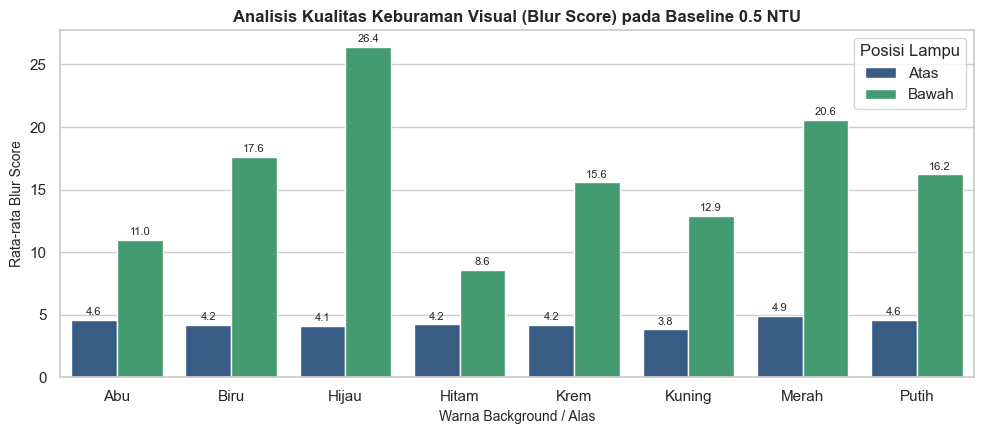

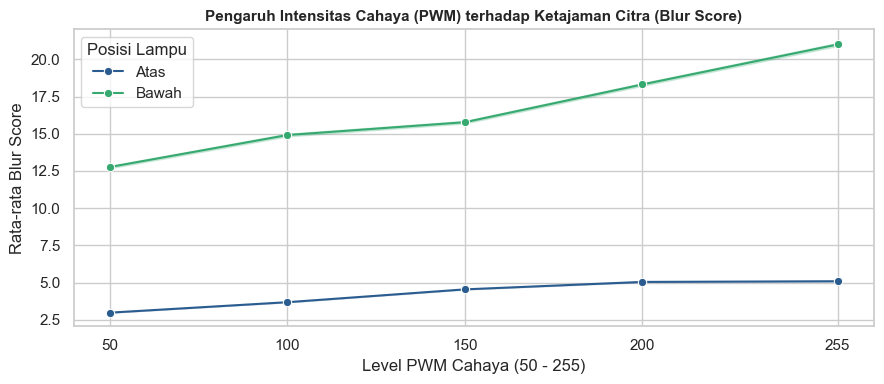

Grafik tersimpan di: C:\Users\Lenovo\Documents\S2\Semester 1\Sains Data\output_eda


In [9]:
# -*- coding: utf-8 -*-
"""
Membuat ulang Grafik 2 (blur per warna & posisi lampu) dan Grafik 3 (PWM vs blur)
langsung dari CSV hasil run (tanpa membaca citra). Berdiri sendiri: semua variabel didefinisikan di sini.
"""
import os

import matplotlib.pyplot as plt
import pandas as pd
import seaborn as sns

OUT = r"C:\Users\Lenovo\Documents\S2\Semester 1\Sains Data\output_eda"   # folder OUT_DIR program utama

df = pd.read_csv(os.path.join(OUT, "eda_blur_per_citra.csv"))
df["warna_bg"] = df["warna_bg"].str.strip().str.capitalize()

pal_lampu = {"Atas": "#2b5c8f", "Bawah": "#36a970"}


def tampil(nama_file):
    plt.tight_layout()
    plt.savefig(os.path.join(OUT, nama_file), dpi=200, bbox_inches="tight")
    plt.show()


sns.set_theme(style="whitegrid")

# ---------------- Grafik 2: blur score per warna alas dan posisi lampu ----------------
urut_warna = sorted(df["warna_bg"].unique())
plt.figure(figsize=(10, 4.5))
ax = sns.barplot(data=df, x="warna_bg", y="blur_score", order=urut_warna, hue="posisi_lampu",
                 hue_order=["Atas", "Bawah"], errorbar=None, palette=pal_lampu)
for wadah in ax.containers:                      # tulis nilai di atas batang (cocok dengan tabel)
    ax.bar_label(wadah, fmt="%.1f", fontsize=8, padding=2)
plt.title("Analisis Kualitas Keburaman Visual (Blur Score) pada Baseline 0.5 NTU", fontsize=12, fontweight="bold")
plt.xlabel("Warna Background / Alas", fontsize=10)
plt.ylabel("Rata-rata Blur Score", fontsize=10)
plt.legend(title="Posisi Lampu")
tampil("grafik_2_blur_warna_lampu.png")

# ---------------- Grafik 3: PWM vs blur score ----------------
plt.figure(figsize=(9, 4))
sns.lineplot(data=df, x="pwm_cahaya", y="blur_score", hue="posisi_lampu", hue_order=["Atas", "Bawah"],
             marker="o", errorbar="se", palette=pal_lampu)
plt.xticks(sorted(df["pwm_cahaya"].unique()))
plt.title("Pengaruh Intensitas Cahaya (PWM) terhadap Ketajaman Citra (Blur Score)", fontsize=11, fontweight="bold")
plt.xlabel("Level PWM Cahaya (50 - 255)")
plt.ylabel("Rata-rata Blur Score")
plt.legend(title="Posisi Lampu")
tampil("grafik_3_pwm_vs_blur.png")

print("Grafik tersimpan di:", OUT)

In [13]:
# -*- coding: utf-8 -*-
"""
EDA_bahan_ppt.py - menyiapkan SEMUA bahan untuk PPT EDA, sesuai catatan dosen:

  1. contoh dataset udang          -> fig_contoh_*.png
  2. aplikasi EDA ada di mana      -> fig_posisi_eda_pipeline.png
  3. output setelah pakai EDA      -> manifest_dataset_setelah_EDA.csv + fig_funnel_output_eda.png
  4. EDA yang dilakukan apa        -> tabel "EDA yang dilakukan"
  5. temuan EDA di tesis           -> daftar temuan otomatis (berisi angka)
  6. jika kondisi X maka lakukan Y -> tabel keputusan "jika-maka" (dengan jumlah kasus nyata)
  7. pakai tools apa               -> tabel tools + versi
  8. distribusi gambar             -> fig_distribusi_*.png, fig_cakupan_label_heatmap.png, dst.

Masukan : CSV hasil program utama (eda_blur_per_citra.csv, eda_cakupan_label_per_kondisi.csv)
          + folder citra dan folder JSON (hanya untuk gambar contoh/overlay).
Keluaran: folder  <CSV_DIR>\\bahan_ppt  berisi PNG, CSV, dan bahan_ppt.md (ringkasan siap salin).
Tidak membaca ulang seluruh citra, jadi cepat.
"""
import glob
import json
import os
import platform
import re
import sys
import traceback

import cv2
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns
from matplotlib.patches import FancyBboxPatch

# =====================================================================
# KONFIGURASI
# =====================================================================
CSV_DIR = r"C:\Users\Lenovo\Documents\S2\Semester 1\Sains Data\output_eda"
IMG_DIR = r"C:\Users\Lenovo\Documents\S2\Program\Dataset\Raw_Dataset"
LBL_DIR = r"C:\Users\Lenovo\Documents\S2\Program\Dataset\Labeling\Json"
OUT = os.path.join(CSV_DIR, "bahan_ppt")
SEED = 42
BLUR_PCTL = 0.01          # ambang "kandidat severe blur" = persentil ke-1 per posisi lampu
EKSTREM_FRAC = 0.50       # box > 50% luas frame dianggap ekstrem (cek label)
RES_STANDAR = (1920, 1080)

os.makedirs(OUT, exist_ok=True)
rng = np.random.default_rng(SEED)
sns.set_theme(style="whitegrid")
pd.set_option("display.width", 250)
pd.set_option("display.max_columns", None)

# =====================================================================
# KONSTANTA & HELPER
# =====================================================================
KELAS = {"small": "Small (4-7 cm)", "medium": "Medium (8-10 cm)", "large": "Large (11-15 cm)"}
URUT = list(KELAS.values())
KEY_OF = {v: k for k, v in KELAS.items()}
SIZE_FOLDERS = {"Small_Shrimp": "small", "Medium_Shrimp": "medium", "Large_Shrimp": "large"}
WARNA_URUT = ["Abu", "Biru", "Hijau", "Hitam", "Krem", "Kuning", "Merah", "Putih"]
WARNA = {w.lower() for w in WARNA_URUT}
ALIAS = {"hljau": "hijau"}
PWM_OK = {50, 100, 150, 200, 255}
POSISI = {"a": "Atas", "b": "Bawah"}
POS_KEY = {"Atas": "a", "Bawah": "b"}
LAMPU_PWM = [f"{l}-{p}" for l in ("Atas", "Bawah") for p in (50, 100, 150, 200, 255)]
PAL = {"Atas": "#2b5c8f", "Bawah": "#36a970"}
JSON_PAT = re.compile(r"^(?:labels[_-])?(small|medium|large)[_-]([a-z]+)[_-]([ab])[_-](\d+)(?:[_-].*)?$", re.I)
FOLDER_OK = re.compile(r"^(?:[kKlL]_)?(Abu|Biru|Hijau|Hitam|Krem|Kuning|Merah|Putih)_[AB]_(50|100|150|200|255)$")


def parse_meta(name):
    tok = [ALIAS.get(t, t) for t in os.path.splitext(os.path.basename(name))[0].lower().split("_")]
    warna = next((t for t in tok if t in WARNA), None)
    posisi = next((t for t in tok if t in ("a", "b")), None)
    if posisi is None and tok and len(tok[0]) == 2 and tok[0][1] in "ab":
        posisi = tok[0][1]
    pwm = next((int(t) for t in tok if t.isdigit() and int(t) in PWM_OK), None)
    return warna, posisi, pwm


def meta_from_json_name(path):
    m = JSON_PAT.match(os.path.splitext(os.path.basename(path))[0])
    if not m:
        return None
    kelas, warna, posisi, pwm = m.groups()
    return kelas.lower(), ALIAS.get(warna.lower(), warna.lower()), posisi.lower(), int(pwm)


def simpan(nama):
    plt.tight_layout()
    plt.savefig(os.path.join(OUT, nama), dpi=200, bbox_inches="tight")
    plt.close("all")
    print("   gambar:", nama)


def simpan_csv(d, nama, index=True):
    d.to_csv(os.path.join(OUT, nama), index=index)
    print("   tabel :", nama)


def md_tabel(d, index=True, fmt="{:,.2f}"):
    d = d.reset_index() if index else d.copy()
    cols = list(d.columns)
    baris = ["| " + " | ".join(map(str, cols)) + " |", "|" + "---|" * len(cols)]
    for _, r in d.iterrows():
        sel = []
        for v in r:
            if isinstance(v, (int, np.integer)):
                sel.append(f"{v:,}")
            elif isinstance(v, (float, np.floating)):
                sel.append("" if np.isnan(v) else fmt.format(v))
            else:
                sel.append(str(v))
        baris.append("| " + " | ".join(sel) + " |")
    return "\n".join(baris)


def jalankan(nama, fn):
    print(f"\n>> {nama}")
    try:
        return fn()
    except Exception:
        print(f"[GAGAL] {nama} (bagian lain tetap dilanjutkan):")
        traceback.print_exc()
        return None


# =====================================================================
# MUAT DATA
# =====================================================================
df = pd.read_csv(os.path.join(CSV_DIR, "eda_blur_per_citra.csv"))
cov = pd.read_csv(os.path.join(CSV_DIR, "eda_cakupan_label_per_kondisi.csv"))
for d in (df, cov):
    d["warna_bg"] = d["warna_bg"].str.strip().str.capitalize()
    d["kond"] = d["posisi_lampu"] + "-" + d["pwm_cahaya"].astype(int).astype(str)

df["ada_label"] = df["box_area_px"] > 0
df["box_area_frac"] = np.where(df["ada_label"], df["box_area_px"] / (df["img_w"] * df["img_h"]), np.nan)
rasio = df["blur_score"] / df["blur_norm"].replace(0, np.nan)
df["brightness_est"] = np.sqrt((rasio - 1e-6).clip(lower=0))      # kecerahan rata-rata (0-255) hasil turunan blur_norm
df["frame_no"] = df["filename"].str.extract(r"_(\d+)\.[A-Za-z0-9]+$")[0].astype(float)
df["kelas_ord"] = df["ukuran_kelas"].map({k: i + 1 for i, k in enumerate(URUT)})
df["lampu_bawah"] = (df["posisi_lampu"] == "Bawah").astype(int)
lab = df[df["ada_label"]].copy()
KOND4 = ["ukuran_kelas", "warna_bg", "posisi_lampu", "pwm_cahaya"]

N_ALL = len(df)
print(f"Data dimuat: {N_ALL:,} citra, {int(df['ada_label'].sum()):,} berlabel, {len(cov)} kondisi.")
REPORT = {}      # bagian markdown per nomor catatan dosen
EXTRA = {}


# =====================================================================
# 8. DISTRIBUSI GAMBAR
# =====================================================================
def sec_distribusi():
    ring = cov.groupby("ukuran_kelas").agg(n_kondisi=("kond", "size"), n_citra=("n_citra", "sum"),
                                           n_label=("n_label_cocok", "sum")).reindex(URUT)
    ring["cakupan_label_pct"] = 100 * ring["n_label"] / ring["n_citra"]
    ring["n_kondisi_berlabel"] = cov[cov["n_label_cocok"] > 0].groupby("ukuran_kelas").size().reindex(URUT).fillna(0).astype(int)
    simpan_csv(ring, "tabel_distribusi_per_kelas.csv")

    # (a) jumlah citra per kelas + per posisi lampu
    fig, ax = plt.subplots(1, 2, figsize=(11, 4))
    sns.barplot(x=ring.index, y=ring["n_citra"], hue=ring.index, order=URUT, palette="Set2", legend=False, ax=ax[0])
    for i, v in enumerate(ring["n_citra"]):
        ax[0].text(i, v, f"{int(v):,}", ha="center", va="bottom", fontsize=9)
    ax[0].set_title("Jumlah citra per kelas ukuran"); ax[0].set_xlabel(""); ax[0].set_ylabel("Jumlah citra")
    pv = cov.pivot_table(index="ukuran_kelas", columns="posisi_lampu", values="n_citra", aggfunc="sum").reindex(URUT)
    pv[["Atas", "Bawah"]].plot(kind="bar", stacked=True, color=[PAL["Atas"], PAL["Bawah"]], ax=ax[1], rot=0)
    ax[1].set_title("Per posisi lampu"); ax[1].set_xlabel(""); ax[1].set_ylabel("Jumlah citra"); ax[1].legend(title="Posisi lampu")
    simpan("fig_distribusi_jumlah_citra.png")

    # (b) heatmap jumlah citra per kondisi, tiap kelas
    for nama, kolom, fmt, cmap, kw, judul in [
        ("fig_distribusi_kondisi_heatmap.png", "n_citra", ".0f", "Blues", {}, "Jumlah citra"),
        ("fig_cakupan_label_heatmap.png", "cakupan_pct", ".0f", "RdYlGn", dict(vmin=0, vmax=100), "Cakupan label (%)"),
    ]:
        fig, axes = plt.subplots(1, 3, figsize=(18, 4.2), sharey=True)
        for ax, k in zip(axes, URUT):
            pt = (cov[cov["ukuran_kelas"] == k].pivot_table(index="warna_bg", columns="kond", values=kolom, aggfunc="mean")
                  .reindex(index=WARNA_URUT, columns=LAMPU_PWM))
            sns.heatmap(pt, annot=True, fmt=fmt, cmap=cmap, cbar=False, linewidths=.5, ax=ax, annot_kws={"size": 7}, **kw)
            ax.set_title(f"{k}", fontsize=10); ax.set_xlabel("Posisi lampu - PWM"); ax.set_ylabel("")
            ax.tick_params(axis="x", labelsize=7)
        fig.suptitle(f"{judul} per kondisi (warna alas x lampu-PWM)", fontweight="bold")
        simpan(nama)

    # (c) resolusi
    res = df.groupby(["ukuran_kelas", "img_w", "img_h"]).size().rename("n_citra").reset_index()
    res["resolusi"] = res["img_w"].astype(int).astype(str) + "x" + res["img_h"].astype(int).astype(str)
    simpan_csv(res, "tabel_resolusi.csv", index=False)
    pr = res.pivot_table(index="ukuran_kelas", columns="resolusi", values="n_citra", aggfunc="sum").reindex(URUT).fillna(0)
    pr.plot(kind="bar", stacked=True, figsize=(7, 4), rot=0, colormap="Set2")
    plt.title("Resolusi citra per kelas"); plt.xlabel(""); plt.ylabel("Jumlah citra")
    simpan("fig_distribusi_resolusi.png")

    REPORT[8] = (ring, res)


jalankan("8. distribusi gambar", sec_distribusi)


# =====================================================================
# 4/5. STATISTIK, KORELASI, UKURAN BOX
# =====================================================================
def deskriptif(d, kolom):
    g = d.groupby("ukuran_kelas")[kolom]
    t = g.agg(n="count", mean="mean", median="median", sd="std", min="min", max="max")
    t["q1"], t["q3"] = g.quantile(.25), g.quantile(.75)
    t["iqr"] = t["q3"] - t["q1"]
    t["skew"] = g.skew()
    return t.reindex(URUT)


def sec_statistik():
    # tabel deskriptif beberapa variabel
    bagian = []
    for kolom, nama in [("box_area_px", "Luas box (px2)"), ("box_area_frac", "Luas box / luas frame"),
                        ("blur_score", "Blur score (Var. Laplacian)"), ("brightness_est", "Kecerahan (turunan)")]:
        t = deskriptif(lab if kolom.startswith("box") else df, kolom)
        t.insert(0, "variabel", nama)
        bagian.append(t)
    desk = pd.concat(bagian)
    simpan_csv(desk, "tabel_deskriptif.csv")

    # IQR luas box per kelas
    q = lab.groupby("ukuran_kelas")["box_area_px"].quantile([.25, .75]).unstack()
    q.columns = ["q1", "q3"]
    q["iqr"] = q["q3"] - q["q1"]
    q["batas_bawah"], q["batas_atas"] = q["q1"] - 1.5 * q["iqr"], q["q3"] + 1.5 * q["iqr"]
    q = q.reindex(URUT)
    n_out = {}
    for k in URUT:
        s = lab.loc[lab["ukuran_kelas"] == k, "box_area_px"]
        n_out[k] = int(((s < q.loc[k, "batas_bawah"]) | (s > q.loc[k, "batas_atas"])).sum())
    q["n"] = lab.groupby("ukuran_kelas").size().reindex(URUT)
    q["n_outlier"] = pd.Series(n_out)
    q["outlier_pct"] = 100 * q["n_outlier"] / q["n"]
    simpan_csv(q, "tabel_iqr_outlier_luas_box.csv")
    df["flag_area_outlier"] = df["ada_label"] & ((df["box_area_px"] < df["ukuran_kelas"].map(q["batas_bawah"])) |
                                                 (df["box_area_px"] > df["ukuran_kelas"].map(q["batas_atas"])))
    lab["flag_area_outlier"] = df.loc[lab.index, "flag_area_outlier"]

    # sebaran outlier per kondisi
    ok = lab.groupby(KOND4)["flag_area_outlier"].agg(n_frame="size", n_outlier="sum").reset_index()
    ok = ok[ok["n_outlier"] > 0].sort_values("n_outlier", ascending=False)
    simpan_csv(ok, "tabel_outlier_per_kondisi.csv", index=False)

    # boxplot luas box per kelas
    fig, ax = plt.subplots(1, 2, figsize=(12, 4.5))
    sns.boxplot(data=lab, x="ukuran_kelas", y="box_area_px", order=URUT, hue="ukuran_kelas", hue_order=URUT,
                palette="Set2", legend=False, showmeans=True, fliersize=2, ax=ax[0])
    ax[0].set_title("Luas bounding box polygon (px2)"); ax[0].set_xlabel(""); ax[0].set_ylabel("px2")
    sns.boxplot(data=lab, x="ukuran_kelas", y="box_area_frac", order=URUT, hue="ukuran_kelas", hue_order=URUT,
                palette="Set2", legend=False, showmeans=True, fliersize=2, ax=ax[1])
    ax[1].set_title("Luas box relatif terhadap frame"); ax[1].set_xlabel(""); ax[1].set_ylabel("luas box / luas frame")
    simpan("fig_boxplot_luas_box.png")

    # luas box menurut posisi lampu (sensitivitas pengukuran terhadap kondisi akuisisi)
    plt.figure(figsize=(8, 4.5))
    sns.boxplot(data=lab, x="ukuran_kelas", y="box_area_frac", hue="posisi_lampu", order=URUT, hue_order=["Atas", "Bawah"],
                palette=PAL, showfliers=False)
    plt.title("Luas box relatif menurut posisi lampu"); plt.xlabel(""); plt.ylabel("luas box / luas frame")
    plt.legend(title="Posisi lampu")
    simpan("fig_luas_box_vs_lampu.png")

    # median luas relatif per kondisi (heatmap)
    fig, axes = plt.subplots(1, 3, figsize=(18, 4.2), sharey=True)
    for ax, k in zip(axes, URUT):
        pt = (lab[lab["ukuran_kelas"] == k].pivot_table(index="warna_bg", columns="kond", values="box_area_frac", aggfunc="median") * 100)
        pt = pt.reindex(index=WARNA_URUT, columns=LAMPU_PWM)
        sns.heatmap(pt, annot=True, fmt=".1f", cmap="YlGnBu", cbar=False, linewidths=.5, ax=ax, annot_kws={"size": 7})
        ax.set_title(k, fontsize=10); ax.set_xlabel("Posisi lampu - PWM"); ax.set_ylabel("")
        ax.tick_params(axis="x", labelsize=7)
    fig.suptitle("Median luas box (% luas frame) per kondisi", fontweight="bold")
    simpan("fig_luas_box_median_kondisi.png")

    # sensitivitas: rentang median antar kondisi (kondisi dengan >=30 frame)
    cm = lab.groupby(["ukuran_kelas", "warna_bg", "kond"])["box_area_frac"].agg(["median", "size"]).reset_index()
    cm = cm[cm["size"] >= 30]
    sens = cm.groupby("ukuran_kelas")["median"].agg(median_antar_kondisi="median", minimum="min", maksimum="max").reindex(URUT)
    sens["rentang_relatif_pct"] = 100 * (sens["maksimum"] - sens["minimum"]) / sens["median_antar_kondisi"]
    simpan_csv(sens, "tabel_sensitivitas_luas_box_antar_kondisi.csv")

    # blur: heatmap warna x kondisi
    fig, ax = plt.subplots(1, 2, figsize=(15, 4.2), sharey=True)
    p1 = df.pivot_table(index="warna_bg", columns="kond", values="blur_score", aggfunc="mean").reindex(index=WARNA_URUT, columns=LAMPU_PWM)
    sns.heatmap(p1, annot=True, fmt=".1f", cmap="YlGn", cbar=False, linewidths=.5, ax=ax[0], annot_kws={"size": 7})
    ax[0].set_title("Rata-rata blur score (mentah)"); ax[0].set_xlabel("Posisi lampu - PWM"); ax[0].set_ylabel("")
    p2 = df.pivot_table(index="warna_bg", columns="kond", values="blur_norm", aggfunc="median").reindex(index=WARNA_URUT, columns=LAMPU_PWM) * 1000
    sns.heatmap(p2, annot=True, fmt=".1f", cmap="YlGn", cbar=False, linewidths=.5, ax=ax[1], annot_kws={"size": 7})
    ax[1].set_title("Median blur_norm x 1000 (dinormalkan kecerahan)"); ax[1].set_xlabel("Posisi lampu - PWM"); ax[1].set_ylabel("")
    for a in ax:
        a.tick_params(axis="x", labelsize=7)
    simpan("fig_blur_heatmap_kondisi.png")

    # korelasi Spearman
    kol = ["pwm_cahaya", "lampu_bawah", "kelas_ord", "blur_score", "blur_norm", "brightness_est", "box_area_frac"]
    nama = {"pwm_cahaya": "PWM", "lampu_bawah": "Lampu bawah", "kelas_ord": "Kelas (1-3)", "blur_score": "Blur score",
            "blur_norm": "Blur norm", "brightness_est": "Kecerahan", "box_area_frac": "Luas box rel."}
    cor = df[kol].rename(columns=nama).corr(method="spearman")
    plt.figure(figsize=(7.5, 6))
    sns.heatmap(cor, annot=True, fmt=".2f", cmap="coolwarm", vmin=-1, vmax=1, linewidths=.5, cbar_kws={"label": "Spearman"})
    plt.title("Korelasi antar variabel")
    simpan("fig_korelasi_spearman.png")
    simpan_csv(cor, "tabel_korelasi_spearman.csv")

    REPORT[4] = (desk, q, ok, sens, cor)


jalankan("4/5. statistik, outlier, korelasi", sec_statistik)

# =====================================================================
# 3. OUTPUT SETELAH EDA: manifest + funnel
# =====================================================================
FUNNEL = {}


def sec_manifest():
    if "flag_area_outlier" not in df:
        df["flag_area_outlier"] = False
    ambang = df.groupby("posisi_lampu")["blur_score"].transform(lambda s: s.quantile(BLUR_PCTL))
    df["flag_blur_kandidat"] = df["blur_score"] < ambang
    df["flag_ekstrem"] = df["box_area_frac"] > EKSTREM_FRAC
    df["flag_resolusi"] = ~((df["img_w"] == RES_STANDAR[0]) & (df["img_h"] == RES_STANDAR[1]))
    bermasalah = df["flag_blur_kandidat"] | df["flag_area_outlier"] | df["flag_ekstrem"] | df["flag_resolusi"]
    df["status"] = np.where(~df["ada_label"], "perlu_label", np.where(bermasalah, "tinjau", "layak_training"))
    kol = KOND4 + ["filename", "img_w", "img_h", "ada_label", "blur_score", "blur_norm", "box_area_px", "box_area_frac",
                   "flag_blur_kandidat", "flag_area_outlier", "flag_ekstrem", "flag_resolusi", "status"]
    simpan_csv(df[kol], "manifest_dataset_setelah_EDA.csv", index=False)

    # funnel bertahap
    m1 = df["ada_label"]
    m2 = m1 & ~df["flag_blur_kandidat"]
    m3 = m2 & ~df["flag_area_outlier"] & ~df["flag_ekstrem"]
    m4 = m3 & ~df["flag_resolusi"]
    langkah = [("Citra terbaca", pd.Series(True, index=df.index)), ("Berlabel (JSON)", m1),
               ("Lolos kandidat blur", m2), ("Lolos outlier luas box", m3), ("Lolos resolusi standar = layak", m4)]
    tab = pd.DataFrame({n: m.groupby(df["ukuran_kelas"]).sum().reindex(URUT) for n, m in langkah}).astype(int)
    tab.loc["Semua kelas"] = tab.sum()
    simpan_csv(tab.T, "tabel_funnel_output_eda.csv")
    FUNNEL["tab"] = tab

    total = [int(m.sum()) for _, m in langkah]
    plt.figure(figsize=(9, 4))
    ax = sns.barplot(y=[n for n, _ in langkah], x=total, color="#0F766E")
    for i, v in enumerate(total):
        pct = f"  ({100 * v / total[0]:.1f}% dari semua citra)"
        ax.text(v, i, f" {v:,}{pct}", va="center", fontsize=9)
    ax.set_xlim(0, total[0] * 1.45)
    ax.set_title("Output EDA: dari seluruh citra menjadi data layak latih")
    ax.set_xlabel("Jumlah citra")
    simpan("fig_funnel_output_eda.png")

    st = df.groupby(["ukuran_kelas", "status"]).size().unstack(fill_value=0).reindex(URUT)
    simpan_csv(st, "tabel_status_per_kelas.csv")
    FUNNEL["status"] = st


jalankan("3. manifest dan funnel", sec_manifest)


# =====================================================================
# 1. CONTOH DATASET (overlay polygon)
# =====================================================================
def sec_contoh():
    if not (os.path.isdir(IMG_DIR) and os.path.isdir(LBL_DIR)):
        print("   IMG_DIR/LBL_DIR tidak ditemukan -> bagian contoh dilewati")
        return
    peta_json = {}
    for jf in glob.glob(os.path.join(LBL_DIR, "**", "*.json"), recursive=True):
        meta = meta_from_json_name(jf)
        if meta:
            peta_json.setdefault(meta, []).append(jf)
    peta_img = {}
    for fk, kk in SIZE_FOLDERS.items():
        kd = os.path.join(IMG_DIR, fk)
        if not os.path.isdir(kd):
            continue
        for sub in os.listdir(kd):
            sd = os.path.join(kd, sub)
            if os.path.isdir(sd):
                w, p, pw = parse_meta(sub)
                if None not in (w, p, pw):
                    peta_img[(kk, w, p, pw)] = sd
    cache_json, cache_list = {}, {}

    def muat(path):
        if path not in cache_json:
            with open(path, "r", encoding="utf-8") as f:
                cache_json[path] = json.load(f)
        return cache_json[path]

    def daftar(folder):
        if folder not in cache_list:
            cache_list[folder] = {f.lower(): f for f in os.listdir(folder) if f.lower().endswith((".jpg", ".png"))}
        return cache_list[folder]

    def ambil(key, nama=None, boleh_tanpa_label=True):
        """Kembalikan (gambar RGB 640 px, ada_polygon) atau None."""
        folder = peta_img.get(key)
        if folder is None:
            return None
        files = daftar(folder)
        poly = None
        pilihan = None
        for jf in peta_json.get(key, []):
            data = muat(jf)
            if nama is not None:
                kunci = next((k for k in data if k.lower() == nama.lower()), None)
                cand = [kunci] if kunci else []
            else:
                cand = sorted(k for k in data if k.lower() in files)
            if cand:
                pilihan = cand[int(rng.integers(len(cand)))]
                reg = data[pilihan]["regions"]
                reg = list(reg.values())[0] if isinstance(reg, dict) else reg[0]
                sa = reg["shape_attributes"]
                poly = list(zip(sa["all_points_x"], sa["all_points_y"]))
                break
        if pilihan is None:
            if nama is not None or not boleh_tanpa_label or not files:
                return None
            pilihan = sorted(files)[int(rng.integers(len(files)))]
        path = os.path.join(folder, files.get(pilihan.lower(), pilihan))
        img = cv2.imread(path)
        if img is None:
            return None
        h, w = img.shape[:2]
        s = 640 / w
        im = cv2.resize(img, (640, int(h * s)))
        if poly:
            pts = (np.array(poly, float) * s).astype(np.int32).reshape(-1, 1, 2)
            ov = im.copy()
            cv2.fillPoly(ov, [pts], (0, 255, 0))
            im = cv2.addWeighted(ov, 0.25, im, 0.75, 0)
            cv2.polylines(im, [pts], True, (0, 255, 0), 2)
            x, y, bw, bh = cv2.boundingRect(pts)
            cv2.rectangle(im, (x, y), (x + bw, y + bh), (255, 200, 0), 1)
        return cv2.cvtColor(im, cv2.COLOR_BGR2RGB), bool(poly)

    def key_dari(kelas_label, warna, lampu, pwm):
        return KEY_OF[kelas_label], warna.lower(), POS_KEY[lampu], int(pwm)

    def montase(tiles, baris, kolom, nama_file, judul):
        fig, axes = plt.subplots(baris, kolom, figsize=(kolom * 4.3, baris * 2.7), squeeze=False)
        for ax in axes.ravel():
            ax.axis("off")
        for ax, (img, jdl) in zip(axes.ravel(), tiles):
            if img is not None:
                ax.imshow(img)
            else:
                ax.text(0.5, 0.5, "tidak tersedia", ha="center", va="center", transform=ax.transAxes)
            ax.set_title(jdl, fontsize=8.5)
        fig.suptitle(judul, fontweight="bold")
        simpan(nama_file)

    def pilih_kondisi(kelas_label, warna, lampu, pwm):
        """Kondisi berlabel terdekat dengan permintaan."""
        c = cov[(cov["ukuran_kelas"] == kelas_label) & (cov["n_label_cocok"] > 0)]
        if c.empty:
            return None
        pers = c[(c["warna_bg"] == warna) & (c["posisi_lampu"] == lampu)]
        if not pers.empty:
            r = pers.iloc[(pers["pwm_cahaya"] - pwm).abs().argsort().iloc[0]]
        else:
            r = c.iloc[int(rng.integers(len(c)))]
        return r["warna_bg"], r["posisi_lampu"], int(r["pwm_cahaya"])

    # --- Gambar 1: contoh tiap kelas pada beberapa warna alas / lampu
    spek = [("Putih", "Bawah", 200), ("Krem", "Atas", 200), ("Biru", "Bawah", 200), ("Merah", "Atas", 200)]
    tiles = []
    for k in URUT:
        for w, l, p in spek:
            kond = pilih_kondisi(k, w, l, p)
            hasil = ambil(key_dari(k, *kond)) if kond else None
            tiles.append((hasil[0] if hasil else None, f"{k.split()[0]} | {kond[0]} | {kond[1]} | PWM {kond[2]}" if kond else k))
    montase(tiles, 3, 4, "fig_contoh_dataset_per_kelas.png",
            "Contoh dataset udang vaname: 3 kelas ukuran x variasi warna alas dan posisi lampu (hijau = polygon label)")

    # --- Gambar 2: variasi lampu dan PWM (satu kelas, satu warna)
    skor = (cov[cov["n_label_cocok"] > 0].groupby(["ukuran_kelas", "warna_bg"]).size().rename("n").reset_index())
    skor["pref"] = (skor["ukuran_kelas"] == URUT[1]).astype(int) * 2 + (skor["warna_bg"] == "Biru").astype(int)
    pil = skor.sort_values(["n", "pref"], ascending=False).iloc[0]
    kk, ww = pil["ukuran_kelas"], pil["warna_bg"]
    tiles = []
    for l in ("Atas", "Bawah"):
        for p in (50, 100, 150, 200, 255):
            hasil = ambil(key_dari(kk, ww, l, p))
            ket = "" if (hasil and hasil[1]) else " (tanpa label)"
            tiles.append((hasil[0] if hasil else None, f"{l} | PWM {p}{ket}"))
    montase(tiles, 2, 5, "fig_contoh_variasi_lampu_pwm.png", f"Variasi posisi lampu dan PWM - kelas {kk}, alas {ww}")

    # --- Gambar 3: kondisi tanpa label (Hitam, Hijau-Atas)
    tiles = []
    for filt, nama in [((cov["warna_bg"] == "Hitam"), "Hitam"), ((cov["warna_bg"] == "Hijau") & (cov["posisi_lampu"] == "Atas"), "Hijau-Atas")]:
        c = cov[filt & (cov["n_label_cocok"] == 0)]
        for k in URUT:
            ck = c[c["ukuran_kelas"] == k]
            if ck.empty:
                tiles.append((None, f"{nama} | {k.split()[0]}"))
                continue
            r = ck.iloc[int(rng.integers(len(ck)))]
            hasil = ambil(key_dari(k, r["warna_bg"], r["posisi_lampu"], r["pwm_cahaya"]))
            tiles.append((hasil[0] if hasil else None, f"{nama} | {k.split()[0]} | {r['posisi_lampu']} | PWM {int(r['pwm_cahaya'])} (belum berlabel)"))
    montase(tiles, 2, 3, "fig_contoh_kondisi_tanpa_label.png", "Contoh kondisi yang belum memiliki label")

    # --- Gambar 4: kasus ekstrem
    def baris_ekstrem(d, kolom, asc, n=3):
        return d.sort_values(kolom, ascending=asc).head(n)
    tiles = []
    for d, ket in [(baris_ekstrem(lab, "box_area_frac", False), "box terbesar"),
                   (baris_ekstrem(lab, "box_area_frac", True), "box terkecil"),
                   (baris_ekstrem(lab, "blur_score", True), "blur terendah")]:
        for _, r in d.iterrows():
            hasil = ambil(key_dari(r["ukuran_kelas"], r["warna_bg"], r["posisi_lampu"], r["pwm_cahaya"]), nama=r["filename"])
            tiles.append((hasil[0] if hasil else None,
                          f"{ket}: {r['ukuran_kelas'].split()[0]} {r['warna_bg']} {r['posisi_lampu']} PWM{int(r['pwm_cahaya'])} | box {100 * r['box_area_frac']:.1f}% frame | blur {r['blur_score']:.1f}"))
    montase(tiles, 3, 3, "fig_contoh_kasus_ekstrem.png", "Kasus ekstrem yang diverifikasi visual (kandidat salah label / citra buruk)")


jalankan("1. contoh dataset (overlay)", sec_contoh)


# =====================================================================
# 2. POSISI EDA DALAM PIPELINE
# =====================================================================
def sec_pipeline():
    fig, ax = plt.subplots(figsize=(15, 5))
    ax.set_xlim(0, 15); ax.set_ylim(0, 5); ax.axis("off")
    tahap = ["Akuisisi data\n(rig akuarium: kamera,\nlampu PWM, sensor)", "Pelabelan\n(polygon udang,\nformat VIA JSON)", "EDA\n(audit & analisis data)",
             "Preprocessing\n(filter blur,\nnormalisasi, resize)", "Split data\n(per rekaman/kondisi)", "YOLOv9-Seg\n(segmentasi udang)",
             "Kalibrasi px->cm\n=> panjang (cm)"]
    x0, lebar, jarak = 0.2, 1.85, 0.30
    for i, t in enumerate(tahap):
        x = x0 + i * (lebar + jarak)
        eda = (i == 2)
        ax.add_patch(FancyBboxPatch((x, 3.0), lebar, 1.4, boxstyle="round,pad=0.05", fc="#0F766E" if eda else "#E5E7EB",
                                    ec="#0F766E" if eda else "#9CA3AF", lw=2))
        ax.text(x + lebar / 2, 3.7, t, ha="center", va="center", fontsize=8.5, color="white" if eda else "#1F2933",
                fontweight="bold" if eda else "normal")
        if i < len(tahap) - 1:
            ax.annotate("", xy=(x + lebar + jarak - 0.03, 3.7), xytext=(x + lebar + 0.03, 3.7), arrowprops=dict(arrowstyle="->", color="#6B7280"))
    xe = x0 + 2 * (lebar + jarak) + lebar / 2
    keluaran = [("Daftar eksklusi / tinjau\n(manifest status data)", 3), ("Ambang blur & aturan outlier", 3),
                ("Rencana split\nanti-kebocoran", 4), ("Konfigurasi akuisisi acuan\n(lampu, PWM, alas)", 0)]
    ax.text(xe, 2.35, "Keluaran EDA yang dipakai tahap berikutnya", ha="center", fontsize=9.5, fontweight="bold", color="#0F766E")
    for j, (teks, target) in enumerate(keluaran):
        xt = 0.9 + j * 3.4
        ax.add_patch(FancyBboxPatch((xt, 0.35), 3.0, 1.2, boxstyle="round,pad=0.05", fc="#F0FDFA", ec="#0F766E"))
        ax.text(xt + 1.5, 0.95, teks, ha="center", va="center", fontsize=8.5)
        ax.annotate("", xy=(xt + 1.5, 1.6), xytext=(xe, 2.7), arrowprops=dict(arrowstyle="-", color="#0F766E", lw=1))
    ax.set_title("Posisi EDA dalam alur penelitian (data baseline 0,5 NTU)", fontweight="bold")
    simpan("fig_posisi_eda_pipeline.png")


jalankan("2. posisi EDA di pipeline", sec_pipeline)


# =====================================================================
# 6/7/4. TABEL: JIKA-MAKA, TOOLS, EDA YANG DILAKUKAN + TEMUAN
# =====================================================================
def versi(m):
    try:
        return __import__(m).__version__
    except Exception:
        return "-"


def sec_tabel_teks():
    # --- hitungan untuk aturan jika-maka
    n_tanpa_label = int((~df["ada_label"]).sum())
    kond_tanpa_json = cov[cov["n_label_cocok"] == 0]
    n_kond_tanpa = len(kond_tanpa_json)
    n_blur = int((df["ada_label"] & df["flag_blur_kandidat"]).sum()) if "flag_blur_kandidat" in df else 0
    n_outl = int(df["flag_area_outlier"].sum()) if "flag_area_outlier" in df else 0
    n_ekst = int(df["flag_ekstrem"].sum()) if "flag_ekstrem" in df else 0
    n_res = int((df["flag_resolusi"]).sum()) if "flag_resolusi" in df else 0
    n_folder_besar = int((cov["n_citra"] > 1000).sum())
    n_label_tak_cocok = int((cov["n_label_json"] - cov["n_label_cocok"]).clip(lower=0).sum())
    n_unreadable = int(max(cov["n_citra"].sum() - N_ALL, 0))
    d = df.dropna(subset=["frame_no"]).sort_values(KOND4 + ["frame_no"])
    gap = d.groupby(KOND4)["frame_no"].diff().dropna()
    share1 = float((gap == 1).mean()) if len(gap) else float("nan")
    nama_aneh = []
    if os.path.isdir(IMG_DIR):
        for fk in SIZE_FOLDERS:
            kd = os.path.join(IMG_DIR, fk)
            if os.path.isdir(kd):
                nama_aneh += [f"{fk}/{s}" for s in os.listdir(kd) if os.path.isdir(os.path.join(kd, s)) and not FOLDER_OK.match(s)]
    titik = None
    p = os.path.join(CSV_DIR, "eda_luas_polygon_per_frame.csv")
    if os.path.exists(p):
        nt = pd.read_csv(p, usecols=["ukuran_kelas", "n_titik"])
        titik = nt.groupby("ukuran_kelas")["n_titik"].median().reindex(URUT)
        EXTRA["kasar"] = (nt["n_titik"] <= 5).groupby(nt["ukuran_kelas"]).mean().reindex(URUT) * 100

    aturan = pd.DataFrame([
        ("Frame tidak punya label", n_tanpa_label, "Jangan dipakai untuk training segmentasi; prioritaskan pelabelan kondisi yang kosong"),
        ("Kondisi (warna x lampu x PWM) tanpa file JSON", n_kond_tanpa, "Tandai sebagai belum siap; lengkapi label atau keluarkan dari eksperimen sementara"),
        ("Blur score di bawah persentil ke-1 (per posisi lampu), berlabel", n_blur, "Periksa visual: buang bila benar-benar buram; pertahankan jika hanya noise ringan (uji robustness)"),
        ("Luas box di luar batas IQR per kelas", n_outl, "Periksa overlay: koreksi bila salah label; pertahankan bila variasi pose/jarak valid"),
        (f"Luas box > {int(EKSTREM_FRAC * 100)}% luas frame", n_ekst, "Anggap kandidat salah label; verifikasi sebelum training"),
        (f"Resolusi bukan {RES_STANDAR[0]}x{RES_STANDAR[1]}", n_res, "Resize ke resolusi standar (atau pisahkan) agar skala piksel seragam"),
        ("Folder kondisi berisi > 1000 citra", n_folder_besar, "Cek rekaman ganda/duplikat sebelum dihitung sebagai data independen"),
        ("Label JSON tanpa citra pasangan", n_label_tak_cocok, "Cek penamaan citra atau citra yang terhapus; sinkronkan"),
        ("Citra tidak terbaca (file ada, gagal dibuka)", n_unreadable, "Buang / unduh ulang"),
        ("Nama folder tidak baku (typo/huruf)", len(nama_aneh), "Seragamkan nama folder: " + (", ".join(nama_aneh[:6]) if nama_aneh else "-")),
        ("Frame berurutan (selisih nomor frame = 1)", f"{100 * share1:.1f}% pasangan" if share1 == share1 else "-",
         "Split per rekaman/kondisi, bukan per frame acak (hindari kebocoran)"),
    ], columns=["Jika kondisi", "Jumlah kasus", "Maka tindakan"])
    simpan_csv(aturan, "tabel_jika_maka.csv", index=False)

    versi_py = platform.python_version()
    tools = pd.DataFrame([
        ("Python", versi_py, "Bahasa pemrograman seluruh pipeline EDA"),
        ("OpenCV (cv2)", versi("cv2"), "Membaca citra, Variance of Laplacian (blur), menggambar overlay polygon"),
        ("NumPy", versi("numpy"), "Perhitungan luas bounding box polygon, kuartil"),
        ("pandas", versi("pandas"), "Agregasi per kelas/warna/lampu/PWM, tabel IQR, manifest"),
        ("Matplotlib", versi("matplotlib"), "Grafik dan montase gambar contoh"),
        ("Seaborn", versi("seaborn"), "Boxplot, barplot, heatmap, korelasi"),
        ("Format label", "VIA JSON (polygon) & YOLO-seg .txt", "Label polygon udang; JSON dibaca langsung untuk luas box"),
        ("ESP32", "-", "Kontrol PWM lampu dan sensor kekeruhan pada rig akuarium"),
    ], columns=["Tool", "Versi", "Peran dalam EDA"])
    simpan_csv(tools, "tabel_tools.csv", index=False)

    eda = pd.DataFrame([
        ("Audit integritas data", "Hitung file terbaca, kondisi lengkap, label-citra cocok, nama baku, resolusi", "Python + pandas + OpenCV", "tabel_jika_maka.csv, tabel_resolusi.csv"),
        ("Distribusi citra", "Jumlah citra per kelas dan kondisi (warna x lampu x PWM)", "pandas + Seaborn", "fig_distribusi_*.png"),
        ("Cakupan label", "Frame berlabel / seluruh citra per kondisi", "pandas + Seaborn", "fig_cakupan_label_heatmap.png"),
        ("Statistik deskriptif", "Mean, median, SD, kuartil, skewness per kelas", "pandas", "tabel_deskriptif.csv"),
        ("Ukuran objek (luas box polygon)", "Bounding box polygon dari JSON, absolut dan relatif terhadap frame", "NumPy + pandas", "fig_boxplot_luas_box.png"),
        ("Deteksi outlier", "IQR (Q1-1,5 IQR, Q3+1,5 IQR) per kelas", "pandas", "tabel_iqr_outlier_luas_box.csv"),
        ("Kualitas citra", "Variance of Laplacian (mentah dan dinormalkan kecerahan)", "OpenCV", "fig_blur_heatmap_kondisi.png"),
        ("Hubungan antar variabel", "Korelasi Spearman (PWM, lampu, kelas, blur, kecerahan, luas box)", "pandas + Seaborn", "fig_korelasi_spearman.png"),
        ("Inspeksi visual", "Overlay polygon pada contoh acak dan kasus ekstrem", "OpenCV + Matplotlib", "fig_contoh_*.png"),
        ("Pemeriksaan risiko kebocoran", "Selisih nomor frame berurutan dalam satu kondisi", "pandas", "tabel_jika_maka.csv"),
    ], columns=["EDA yang dilakukan", "Metode", "Tools", "Keluaran"])
    simpan_csv(eda, "tabel_eda_yang_dilakukan.csv", index=False)
    REPORT[67] = (aturan, tools, eda, titik, share1, nama_aneh)


jalankan("6/7/4. tabel jika-maka, tools, EDA yang dilakukan", sec_tabel_teks)


# =====================================================================
# 5. TEMUAN OTOMATIS + bahan_ppt.md
# =====================================================================
def sec_temuan_dan_md():
    T = []
    ring, res = REPORT.get(8, (None, None))
    if ring is not None:
        tot, lab_tot = int(ring["n_citra"].sum()), int(ring["n_label"].sum())
        T.append(f"Dataset baseline 0,5 NTU berisi {tot:,} citra pada {len(cov)} kondisi; "
                 f"Small {int(ring.loc[URUT[0], 'n_citra']):,}, Medium {int(ring.loc[URUT[1], 'n_citra']):,}, Large {int(ring.loc[URUT[2], 'n_citra']):,} (kelas tidak seimbang).")
        T.append(f"Label JSON terbaca untuk {lab_tot:,} frame ({100 * lab_tot / tot:.1f}%); cakupan per kelas: "
                 + ", ".join(f"{k.split()[0]} {ring.loc[k, 'cakupan_label_pct']:.1f}%" for k in URUT)
                 + f". {int((cov['n_label_cocok'] == 0).sum())} kondisi belum berlabel.")
    if lab is not None and len(lab):
        q = lab.groupby("ukuran_kelas")["box_area_px"].quantile([.25, .5, .75]).unstack()
        sep = all(q.loc[URUT[i], 0.75] < q.loc[URUT[i + 1], 0.25] for i in range(2))
        T.append("Median luas box polygon: " + "; ".join(f"{k.split()[0]} {q.loc[k, 0.5]:,.0f} px2" for k in URUT)
                 + (". Kotak Q1-Q3 antar kelas tidak tumpang tindih." if sep else ". Kotak Q1-Q3 antar kelas tumpang tindih sebagian."))
        mf = lab.groupby("ukuran_kelas")["box_area_frac"].median().reindex(URUT) * 100
        T.append("Dalam persen luas frame, median box: " + "; ".join(f"{k.split()[0]} {mf[k]:.1f}%" for k in URUT) + ".")
    ba = df.groupby("posisi_lampu")["blur_score"].mean()
    bm = df.groupby("posisi_lampu")["blur_score"].median()
    bn = df.groupby("posisi_lampu")["blur_norm"].median()
    if {"Atas", "Bawah"} <= set(ba.index):
        T.append(f"Skor Laplacian lampu Bawah vs Atas: rata-rata {ba['Bawah']:.2f} vs {ba['Atas']:.2f} ({ba['Bawah'] / ba['Atas']:.1f} kali); "
                 f"median {bm['Bawah']:.2f} vs {bm['Atas']:.2f} ({bm['Bawah'] / bm['Atas']:.1f} kali); "
                 f"median blur_norm (dinormalkan kecerahan) Bawah/Atas = {bn['Bawah'] / bn['Atas']:.2f} kali.")
    if "flag_blur_kandidat" in df and df["flag_blur_kandidat"].any():
        fb = df[df["flag_blur_kandidat"]]
        wt = fb["warna_bg"].value_counts(normalize=True)
        T.append(f"Kandidat severe blur (persentil ke-{int(BLUR_PCTL * 100)} per lampu) = {len(fb):,} citra; "
                 f"{100 * (~fb['ada_label']).mean():.1f}% berada pada citra tanpa label; warna terbanyak: {wt.index[0]} ({100 * wt.iloc[0]:.1f}%).")
    bw = df[df["posisi_lampu"] == "Bawah"].groupby("warna_bg")["blur_score"].mean().sort_values(ascending=False)
    if len(bw):
        T.append(f"Pada lampu Bawah, alas dengan skor tertinggi: {bw.index[0]} ({bw.iloc[0]:.1f}); terendah: {bw.index[-1]} ({bw.iloc[-1]:.1f}).")
    for lampu in ("Atas", "Bawah"):
        s = df[df["posisi_lampu"] == lampu]
        T.append(f"Korelasi Spearman PWM dengan blur_score (lampu {lampu}) = {s['pwm_cahaya'].corr(s['blur_score'], method='spearman'):.2f}; "
                 f"dengan blur_norm = {s['pwm_cahaya'].corr(s['blur_norm'], method='spearman'):.2f}.")
    if "flag_area_outlier" in df:
        n_o = int(df["flag_area_outlier"].sum())
        T.append(f"Outlier IQR luas box: {n_o:,} frame ({100 * n_o / max(len(lab), 1):.2f}% dari berlabel)"
                 + ("; sebarannya per kondisi ada di tabel_outlier_per_kondisi.csv." if n_o else "."))
    if 67 in REPORT:
        _, _, _, titik, share1, aneh = REPORT[67]
        if share1 == share1:
            T.append(f"{100 * share1:.1f}% pasangan citra bersebelahan dalam satu kondisi memiliki nomor frame berurutan -> risiko kebocoran bila split acak per frame.")
        if titik is not None:
            T.append("Median jumlah titik polygon per kelas: " + ", ".join(f"{k.split()[0]} {titik[k]:.0f}" for k in URUT) + " (kehalusan label berbeda antar kelas).")
        if "kasar" in EXTRA:
            T.append("Frame dengan polygon kasar (<= 5 titik): " + ", ".join(f"{k.split()[0]} {EXTRA['kasar'][k]:.1f}%" for k in URUT) + ".")
    if FUNNEL.get("status") is not None:
        st = FUNNEL["status"].sum()
        n_l, n_t, n_p = int(st.get("layak_training", 0)), int(st.get("tinjau", 0)), int(st.get("perlu_label", 0))
        T.append(f"Status data setelah aturan EDA: {n_l:,} citra berlabel lolos semua aturan ({100 * n_l / N_ALL:.1f}% dari seluruh citra), "
                 f"{n_t:,} perlu ditinjau, {n_p:,} menunggu label ({100 * n_p / N_ALL:.1f}%).")
    if "flag_resolusi" in df:
        nr = int(df["flag_resolusi"].sum())
        T.append(f"Resolusi: {nr:,} citra ({100 * nr / N_ALL:.1f}%) bukan {RES_STANDAR[0]}x{RES_STANDAR[1]}." if nr else f"Seluruh citra berresolusi {RES_STANDAR[0]}x{RES_STANDAR[1]}.")

    md = ["# Bahan PPT EDA (otomatis)", "", "Semua angka dihitung dari CSV hasil run. Gambar dan tabel berada di folder yang sama.", ""]
    md += ["## 1. Contoh dataset udang", "", "- fig_contoh_dataset_per_kelas.png (3 kelas x variasi warna alas dan lampu)",
           "- fig_contoh_variasi_lampu_pwm.png (efek posisi lampu dan PWM)", "- fig_contoh_kondisi_tanpa_label.png (Hitam, Hijau-Atas)",
           "- fig_contoh_kasus_ekstrem.png (box terbesar/terkecil, blur terendah)", ""]
    md += ["## 2. Aplikasi EDA di mana", "", "- fig_posisi_eda_pipeline.png: EDA berada setelah akuisisi dan pelabelan, sebelum preprocessing, split, dan training.",
           "- Keluaran EDA: daftar eksklusi/tinjau, ambang blur dan aturan outlier, rencana split, konfigurasi akuisisi acuan.", ""]
    md += ["## 3. Output setelah EDA", "", "- manifest_dataset_setelah_EDA.csv (status per citra: layak_training / tinjau / perlu_label)",
           "- fig_funnel_output_eda.png", ""]
    if FUNNEL.get("tab") is not None:
        md += [md_tabel(FUNNEL["tab"].T.rename_axis("Tahap")), ""]
        md += ["Status per kelas:", "", md_tabel(FUNNEL["status"]), ""]
    if 67 in REPORT:
        aturan, tools, eda, _, _, _ = REPORT[67]
        md += ["## 4. EDA yang dilakukan", "", md_tabel(eda, index=False), ""]
    md += ["## 5. Temuan EDA", ""] + [f"{i}. {t}" for i, t in enumerate(T, 1)] + [""]
    if 67 in REPORT:
        md += ["## 6. Jika kondisi ini, maka dilakukan apa", "", md_tabel(aturan, index=False), ""]
        md += ["## 7. Tools", "", md_tabel(tools, index=False), ""]
    md += ["## 8. Distribusi gambar", "", "- fig_distribusi_jumlah_citra.png, fig_distribusi_kondisi_heatmap.png, fig_cakupan_label_heatmap.png, fig_distribusi_resolusi.png", ""]
    if ring is not None:
        md += [md_tabel(ring), ""]
    md += ["## Tambahan: statistik, outlier, korelasi", "", "- fig_boxplot_luas_box.png, fig_luas_box_vs_lampu.png, fig_luas_box_median_kondisi.png, fig_blur_heatmap_kondisi.png, fig_korelasi_spearman.png", ""]
    if 4 in REPORT:
        desk, q, ok, sens, cor = REPORT[4]
        md += ["IQR luas box per kelas:", "", md_tabel(q), "",
               "Sensitivitas luas box relatif antar kondisi (kondisi >= 30 frame):", "", md_tabel(sens), ""]
    with open(os.path.join(OUT, "bahan_ppt.md"), "w", encoding="utf-8") as f:
        f.write("\n".join(md))
    print("\n   ringkasan: bahan_ppt.md")
    print("\nTEMUAN OTOMATIS:")
    for i, t in enumerate(T, 1):
        print(f" {i}. {t}")


jalankan("5. temuan + bahan_ppt.md", sec_temuan_dan_md)
print("\nSelesai. Semua keluaran ada di:", OUT)

Data dimuat: 187,100 citra, 117,613 berlabel, 240 kondisi.

>> 8. distribusi gambar
   tabel : tabel_distribusi_per_kelas.csv
   gambar: fig_distribusi_jumlah_citra.png
   gambar: fig_distribusi_kondisi_heatmap.png
   gambar: fig_cakupan_label_heatmap.png
   tabel : tabel_resolusi.csv
   gambar: fig_distribusi_resolusi.png

>> 4/5. statistik, outlier, korelasi
   tabel : tabel_deskriptif.csv
   tabel : tabel_iqr_outlier_luas_box.csv
   tabel : tabel_outlier_per_kondisi.csv
   gambar: fig_boxplot_luas_box.png
   gambar: fig_luas_box_vs_lampu.png
   gambar: fig_luas_box_median_kondisi.png
   tabel : tabel_sensitivitas_luas_box_antar_kondisi.csv
   gambar: fig_blur_heatmap_kondisi.png
   gambar: fig_korelasi_spearman.png
   tabel : tabel_korelasi_spearman.csv

>> 3. manifest dan funnel
   tabel : manifest_dataset_setelah_EDA.csv
   tabel : tabel_funnel_output_eda.csv
   gambar: fig_funnel_output_eda.png
   tabel : tabel_status_per_kelas.csv

>> 1. contoh dataset (overlay)
   gambar: fig_c